# CV_ExplainableAI_MedicalImaging — Explainable AI & Medical Imaging, made simple
**Gudsky Research Foundation · Research Intake 2026 · Day 37 (final day of the Computer Vision Fundamentals module)**

This is a hands-on notebook of about **90 minutes**. Every idea from the Day 37 notes gets two things: **a plain-language explanation** (look for the 🧒 *In simple words* boxes) and **a small experiment you can run and see**. Nothing is taken on trust: whenever the notebook says a number, that number was printed by the code you are looking at.

> **The one big idea of the day:** a model can give the right answer for the wrong reason. In medicine, that can hurt a patient. *Explainable AI* is the set of tools that lets us look at **why** a model answered, so we can catch the wrong reasons.

## Roadmap (≈ 90 min)
| Part | Topic (Day 37 section) | What you will do | Time |
|---|---|---|---|
| 0 | Setup and data | load a pretrained model, real chest X-rays, and a safe "practice hospital" (synthetic X-rays) | 8 min |
| 1 | Why explainability matters (§1) | catch a model cheating: right answers, wrong reason | 10 min |
| 2 | Interpretable vs explainable (§2) | read a model's mind directly, then see why a CNN needs help | 5 min |
| 3 | Gradient methods: saliency, Grad-CAM (§3) | build Grad-CAM from scratch | 15 min |
| 4 | Perturbation methods: occlusion, LIME, SHAP (§4) | explain a model without opening it | 15 min |
| 5 | Attention (§5) | a small Vision Transformer, attention maps, rollout, and the "is attention an explanation?" debate | 10 min |
| 6 | A fair test of all methods (§5.4, §11) | which method actually finds the lesion? | 5 min |
| 7 | Medical imaging as a high-stakes domain (§6, §7) | real X-rays, CT windowing, 3D cost, imbalance, privacy | 8 min |
| 8 | Architectures: classifier and U-Net (§8) | fine-tune a pretrained ResNet; train a U-Net; Dice vs IoU; explain a segmenter | 12 min |
| 9 | Evaluation, hospitals and regulation (§9) | sensitivity, specificity, thresholds, a model that fails at a second hospital | 8 min |
| 10 | Wrap-up (§10, §11) | debugging checklist run on our own models, glossary, quiz, what PP13 needs | 5 min |

## How to read the boxes
* 🧒 **In simple words** — the idea with an everyday comparison, no jargon.
* 🔧 **How it works** — the steps, short.
* ⚠️ **Watch out** — the usual mistake.
* 🏥 **Why it matters in medicine** — the reason this day exists.

## Honest labels used throughout
* `[measured]` — a number printed by this notebook's code.
* `[simulated]` — comes from the synthetic "practice hospital" images of Part 0. They are made up by code, so they can be explained exactly (we know where every lesion is), but they are **not** real medicine.
* `[computed]` — plain arithmetic on numbers printed earlier (e.g. Bayes' rule).
* `[assumed]` — a value we had to pick (e.g. the cost of a missed patient); in real work a clinical team supplies it.
* `[established]` / `[from the notes]` — a claim from the literature or from the Day 37 PDF, not tested here.

## Scope, stated up front
* The real chest X-rays used here are only **a handful of images** (to *see* real data, not to train on). All **trained** models use the synthetic images, so results show how the *methods* behave, not how good any model is at real diagnosis.
* The graded assignment **PP13** (a real classifier + a real segmenter, each with explanations) is **not** solved here; Part 10 maps each Day 37 idea onto the PP13 requirements.
* Everything runs on a plain CPU. Total run time is printed at the end.

In [1]:
from __future__ import annotations

import io
import math
import os
import ssl
import sys
import time
import urllib.request
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from scipy.stats import spearmanr
from skimage import data as skdata
from skimage.segmentation import slic
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import roc_auc_score, roc_curve

warnings.filterwarnings("ignore", category=UserWarning)
NB_START = time.time()
SEED = 37
QUICK = os.environ.get("XAI_QUICK", "0") == "1"  # smoke-test mode: tiny budgets, same code
DEVICE = torch.device("cpu")  # everything here is small enough for a CPU; a GPU is not needed
DATA_DIR = Path("xai_data")
DATA_DIR.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": False, "image.cmap": "gray"})


def seed_all(seed: int = SEED) -> None:
    torch.manual_seed(seed)
    np.random.seed(seed)


def table(rows: list[list], header: list[str]) -> None:
    """Plain-text table (works anywhere, no extra packages)."""
    w = [max(len(str(r[i])) for r in [header] + rows) for i in range(len(header))]
    line = lambda r: "  ".join(str(c).ljust(w[i]) for i, c in enumerate(r))  # noqa: E731
    print(line(header))
    print("  ".join("-" * x for x in w))
    for r in rows:
        print(line(r))


def download(url: str, dest: Path, timeout: int = 120) -> bool:
    """Download once, cache in xai_data/. Returns False (and says so) instead of crashing when a host is unreachable."""
    if dest.exists() and dest.stat().st_size > 0:
        return True
    try:
        try:
            resp = urllib.request.urlopen(url, timeout=timeout)
        except ssl.SSLError:
            import certifi

            resp = urllib.request.urlopen(url, timeout=timeout, context=ssl.create_default_context(cafile=certifi.where()))
        with resp, open(dest, "wb") as fh:
            fh.write(resp.read())
        return True
    except Exception as exc:  # noqa: BLE001 - we want to report any network problem plainly
        print(f"  could not download {url.split('/')[-1]}: {type(exc).__name__}")
        dest.unlink(missing_ok=True)
        return False


def show_row(images: list[np.ndarray], titles: list[str] | None = None, size: float = 2.4, cmap: str = "gray", vmin=None, vmax=None) -> None:
    fig, axes = plt.subplots(1, len(images), figsize=(size * len(images), size + 0.4))
    axes = np.atleast_1d(axes)
    for i, (ax, im) in enumerate(zip(axes, images)):
        ax.imshow(im, cmap=cmap, vmin=vmin, vmax=vmax)
        ax.axis("off")
        if titles:
            ax.set_title(titles[i], fontsize=9)
    plt.tight_layout()
    plt.show()


seed_all()
print(f"torch {torch.__version__} | device {DEVICE} | QUICK={QUICK}")

Successfully renamed PrivateUse1 backend to 'tpu'. Device: device(type='tpu')
Registered Python module for 'tpu'.
Device type: tpu, Device index: default
Initializing TPU distributed runtime


torch 2.14.1+cpu | device cpu | QUICK=False


## Part 0 — Data and models you will use
Three ingredients, all downloaded from GitHub (so they also work in restricted networks):
1. **A pretrained ResNet-18** (`ImageNet`-trained, from the `timm` project's GitHub release) — used to show Grad-CAM on an ordinary photo and, in Part 8, as the backbone for transfer learning.
2. **A few real chest X-rays** from the public *covid-chestxray-dataset* (Cohen et al., 2020), only to *look at* real data. Only images whose metadata lists a Creative-Commons-**BY** licence are used, and each is credited where it is shown.
3. **A synthetic "practice hospital"** (next cell group) that we generate ourselves, because explainability is easiest to learn when you *know the right answer*.

In [2]:
R18_URL = "https://github.com/rwightman/pytorch-image-models/releases/download/v0.1-rsb-weights/resnet18_a1_0-d63eafa0.pth"
CXR_RAW = "https://raw.githubusercontent.com/ieee8023/covid-chestxray-dataset/master/"
HAVE_R18 = download(R18_URL, DATA_DIR / "resnet18_timm_a1.pth", timeout=300)
HAVE_META = download(CXR_RAW + "metadata.csv", DATA_DIR / "cxr_metadata.csv")
print("pretrained ResNet-18:", "ready" if HAVE_R18 else "NOT available (Parts 3 and 8 will say what they skip)")
print("chest X-ray metadata:", "ready" if HAVE_META else "NOT available (Part 7 will skip the real-image cells)")


def load_resnet18_pretrained() -> nn.Module:
    from torchvision.models import resnet18

    net = resnet18()
    net.load_state_dict(torch.load(DATA_DIR / "resnet18_timm_a1.pth", map_location="cpu"), strict=True)
    return net.eval()


from torchvision.models import ResNet18_Weights  # noqa: E402

IMAGENET_CLASSES = ResNet18_Weights.IMAGENET1K_V1.meta["categories"]  # the 1000 class names (bundled with torchvision)
IMN_MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
IMN_STD = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)

pretrained ResNet-18: ready
chest X-ray metadata: ready


### The "practice hospital": synthetic chest-X-ray-like images `[simulated]`
🧒 **In simple words.** To learn how to *check* a model, it helps to have a test where you already know the answer. So we draw our own tiny "X-rays" with code: two dark lung areas, a bright spine, faint ribs. A "pneumonia" image gets one soft bright **opacity** (a cloudy patch) inside a lung. Because we drew it, we know **exactly where the lesion is**, so we can later ask: *did the model look at the lesion?*

We also add two things that real hospitals really have (§9.4 of the notes):
* a **corner marker** — a small bright "L" burned into the image, like the side markers or text on real scans;
* a **site style** — each hospital's scanner has its own brightness, contrast and noise (site 0 and site 1).

These are just ingredients for experiments; the images are not meant to look like a real radiograph.

{'X': (2400, 1, 64, 64), 'Y': (2400,), 'M': (2400, 1, 64, 64), 'T': (2400,)}
[measured] share of sick patients with the marker: biased train 0.94, clean train 0.50


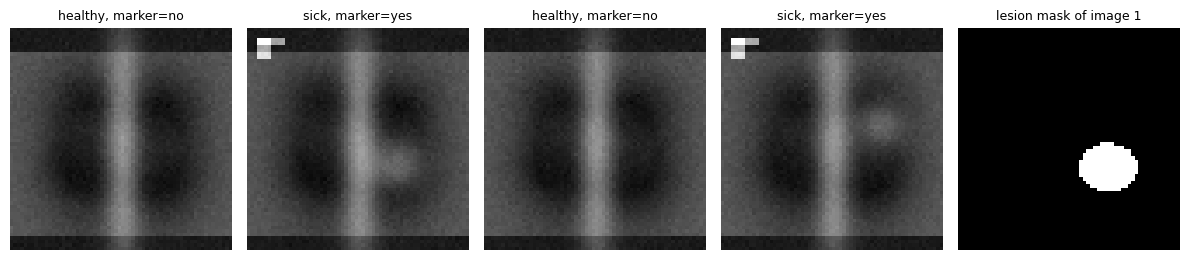

In [3]:
S = 64  # image side in pixels
_yy, _xx = np.mgrid[0:S, 0:S].astype(np.float32)
SITE_STYLE = {0: (1.00, 0.00, 0.015), 1: (1.25, -0.06, 0.030)}  # (contrast gain, brightness bias, noise std) per scanner
TAG_BOX = (slice(3, 9), slice(3, 11))  # where the corner marker is drawn (rows, cols)


def _blob(cx: float, cy: float, sx: float, sy: float) -> np.ndarray:
    return np.exp(-(((_xx - cx) / sx) ** 2 + ((_yy - cy) / sy) ** 2) / 2)


def make_scan(label: int, rng: np.random.Generator, tag: bool, site: int = 0, lesion_amp: float = 0.30) -> tuple[np.ndarray, np.ndarray]:
    """One synthetic scan in [0, 1] plus its exact lesion mask. label 1 = opacity inside a lung field."""
    img = np.full((S, S), 0.10, np.float32)
    lungs = np.clip((_blob(21, 34, 9, 16) + _blob(43, 34, 9, 16)) * 1.3, 0, 1)
    img += 0.25 * (1 - lungs) * (_yy > 6) * (_yy < 60)  # soft tissue is brighter than air-filled lung
    img += 0.45 * _blob(32, 34, 3.5, 24)  # spine and mediastinum
    img += 0.035 * np.sin(_yy / 4.0 + 0.5 * np.sin(_xx / 9)) * lungs  # faint rib shadows
    lesion = np.zeros((S, S), np.float32)
    if label == 1:
        cx = (21 if rng.integers(0, 2) == 0 else 43) + rng.uniform(-4, 4)
        cy = 34 + rng.uniform(-9, 9)
        r = rng.uniform(4.0, 6.0)
        blob = _blob(cx, cy, r, r * rng.uniform(0.8, 1.2))
        img += lesion_amp * blob * lungs.clip(0.3, 1)
        lesion = ((blob > 0.37) & (lungs > 0.25)).astype(np.float32)
    if tag:
        img[3:9, 3:7] += 0.55
        img[3:5, 3:11] += 0.55
    gain, bias, noise = SITE_STYLE[site]
    img = np.clip(img * gain + bias + rng.normal(0, noise, img.shape), 0, 1).astype(np.float32)
    return img, lesion


def build_set(n: int, p_tag_match: float, site: int = 0, amp: float = 0.30, seed: int = 0, positive_frac: float = 0.5) -> dict[str, torch.Tensor]:
    """n scans. `p_tag_match` = probability that the corner marker agrees with the label (marker present <=> sick).
    0.95 = a biased hospital where sick patients are almost always marked; 0.5 = marker unrelated to the label."""
    rng = np.random.default_rng(seed)
    labels = (rng.random(n) < positive_frac).astype(int) if positive_frac != 0.5 else np.arange(n) % 2
    X, M, T = [], [], []
    for lab in labels:
        tag = bool(lab == 1) if rng.random() < p_tag_match else bool(lab == 0)
        im, ls = make_scan(int(lab), rng, tag, site, amp)
        X.append(im), M.append(ls), T.append(tag)
    return dict(X=torch.tensor(np.stack(X))[:, None], Y=torch.tensor(labels), M=torch.tensor(np.stack(M))[:, None], T=torch.tensor(T))


def _n(k: int) -> int:
    return max(k // 8, 64) if QUICK else k


seed_all()
D_TRAIN_BIASED = build_set(_n(2400), 0.95, seed=1)   # hospital where the marker almost always means "sick"
D_TRAIN_CLEAN = build_set(_n(2400), 0.50, seed=2)    # marker carries no information
D_TEST_BIASED = build_set(_n(800), 0.95, seed=3)     # test set with the same bias as the biased training data
D_TEST_CLEAN = build_set(_n(800), 0.50, seed=4)      # marker unrelated to the label
D_TEST_FLIPPED = build_set(_n(800), 0.00, seed=5)    # marker exactly opposite to the label (worst case)
print({k: tuple(v.shape) for k, v in D_TRAIN_CLEAN.items()})
print(f"[measured] share of sick patients with the marker: biased train {D_TRAIN_BIASED['T'][D_TRAIN_BIASED['Y'] == 1].float().mean():.2f}, "
      f"clean train {D_TRAIN_CLEAN['T'][D_TRAIN_CLEAN['Y'] == 1].float().mean():.2f}")

picks = [0, 1, 2, 3]
show_row([D_TRAIN_BIASED["X"][i, 0].numpy() for i in picks] + [D_TRAIN_BIASED["M"][1, 0].numpy()],
         [f"{'sick' if D_TRAIN_BIASED['Y'][i] else 'healthy'}, marker={'yes' if D_TRAIN_BIASED['T'][i] else 'no'}" for i in picks] + ["lesion mask of image 1"],
         vmin=0, vmax=1)


# "Early-stage" scans: same hospital, same scanner, but FAINT lesions (amplitude 0.08 instead of 0.30; D_MID_TEST uses 0.15). Used for clinical-threshold demos,
# because the strong-lesion test sets are so easy that every metric saturates at 1.0.
D_FAINT_TEST = build_set(_n(1000), p_tag_match=0.5, amp=0.08, seed=31)
D_FAINT_VAL = build_set(_n(1000), p_tag_match=0.5, amp=0.08, seed=23)
D_MID_TEST = build_set(_n(800), p_tag_match=0.5, amp=0.15, seed=32)

# Part 1 — Why explainability matters (§1)
### 🧒 In simple words
Imagine a student who gets 100 % on every practice test, because the answer sheet is always stapled in a certain corner and the student only looks at the staple. The marks look perfect. But the student learned **nothing** about the subject — and the day the staple moves, the marks collapse.
Computer-vision models do exactly this. The classic example in the notes (§1.1) is **wolves vs. huskies**: the model scored very well, but it had learned *"snow in the background = wolf"*, not anything about the animals.

### 🏥 Why it matters in medicine
A wrong answer from a vision model does not *look* wrong: a mis-labelled X-ray still looks like a normal X-ray with a label on it (§1.1). A confidently wrong answer is more dangerous than an unsure one, because it invites trust. And real hospitals really do have "staples": scanner markers, text overlays, even the scanner brand's look (§9.4).

### The experiment (all numbers measured below)
We train **two identical small CNNs** on our practice hospital:
* **Model B ("biased")** is trained at a hospital where sick patients' scans *almost always* carry the corner marker (95 %).
* **Model C ("clean")** is trained where the marker has nothing to do with sickness.

Then we test both on three test sets: *biased* (like the training hospital), *clean* (marker unrelated), and *flipped* (marker means the opposite). If a model looks at the lesion, all three scores should be high. If it looks at the marker, the scores will fall apart as soon as the marker stops helping.

In [4]:
class SmallCNN(nn.Module):
    """Three conv blocks + global average pooling. Small on purpose, so it trains in seconds and every layer can be inspected."""

    def __init__(self) -> None:
        super().__init__()
        self.b1 = nn.Sequential(nn.Conv2d(1, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2))   # 64 -> 32
        self.b2 = nn.Sequential(nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2))  # 32 -> 16
        self.b3 = nn.Sequential(nn.Conv2d(32, 64, 3, padding=1), nn.ReLU())                   # 16 x 16 feature maps
        self.head = nn.Linear(64, 2)                                                          # 0 = healthy, 1 = sick

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.head(self.b3(self.b2(self.b1(x))).mean((2, 3)))


def train_classifier(model: nn.Module, X: torch.Tensor, Y: torch.Tensor, epochs: int = 8, lr: float = 2e-3, seed: int = SEED) -> nn.Module:
    g = torch.Generator().manual_seed(seed)
    opt = torch.optim.Adam(model.parameters(), lr)
    for _ in range(epochs):
        model.train()
        perm = torch.randperm(len(X), generator=g)
        for i in range(0, len(X), 64):
            idx = perm[i:i + 64]
            loss = F.cross_entropy(model(X[idx]), Y[idx])
            opt.zero_grad()
            loss.backward()
            opt.step()
    return model.eval()


@torch.no_grad()
def predict_proba(model: nn.Module, X: torch.Tensor, bs: int = 256) -> torch.Tensor:
    """Probability of 'sick' for every image."""
    model.eval()
    return torch.cat([F.softmax(model(X[i:i + bs]), 1)[:, 1] for i in range(0, len(X), bs)])


def accuracy(model: nn.Module, d: dict) -> float:
    return float(((predict_proba(model, d["X"]) > 0.5).long() == d["Y"]).float().mean())


t0 = time.time()
seed_all()
MODEL_B = train_classifier(SmallCNN(), D_TRAIN_BIASED["X"], D_TRAIN_BIASED["Y"], epochs=8 if not QUICK else 2)
seed_all()
MODEL_C = train_classifier(SmallCNN(), D_TRAIN_CLEAN["X"], D_TRAIN_CLEAN["Y"], epochs=8 if not QUICK else 2)
print(f"trained two CNNs in {time.time() - t0:.0f} s")
ACC = {name: [accuracy(m, d) for d in (D_TEST_BIASED, D_TEST_CLEAN, D_TEST_FLIPPED)] for name, m in [("B: biased training", MODEL_B), ("C: clean training", MODEL_C)]}
table([[k] + [f"{v:.3f}" for v in vals] for k, vals in ACC.items()], ["model", "test: biased (marker ~ label)", "test: clean (marker random)", "test: flipped (marker opposite)"])

trained two CNNs in 42 s
model               test: biased (marker ~ label)  test: clean (marker random)  test: flipped (marker opposite)
------------------  -----------------------------  ---------------------------  -------------------------------
B: biased training  0.951                          0.511                        0.000                          
C: clean training   1.000                          1.000                        1.000                          


### What the numbers say
Read the table like a doctor reading a validation report. Model B looks excellent on the test set that shares its training hospital's habit — a normal validation report would have signed it off. But on the *flipped* set its accuracy collapses far **below** 50 %, i.e. worse than a coin: it is confidently predicting the *opposite* of the truth whenever the marker disagrees with the label. Model C, trained without that shortcut, keeps its accuracy on all three sets.

**Nothing in B's accuracy figure revealed this.** To find out *why* B answers the way it does, we need an explanation method — the rest of the notebook. Keep these two models; we will look inside them in Part 3.

⚠️ **Watch out:** a high accuracy on a test set that was collected the same way as the training set tells you the model is good *at that hospital's habits*, not that it learned the disease.

# Part 2 — Interpretability vs. explainability (§2)
### 🧒 In simple words
* **Interpretable model** = a *glass box*. You can open it and read how it thinks, because its structure **is** the explanation. Example: a straight-line (linear) model that adds up *weight × pixel*. The weights tell you what matters.
* **Explainable (post-hoc) technique** = a *flashlight* you shine on a *black box* after it has answered. The box itself stays dark; the flashlight gives you a story about one answer.

A deep CNN has millions of numbers spread over many non-linear layers, so there is nothing to simply "read". That is why Parts 3–5 are all flashlights, not glass boxes. (It is a spectrum, not two boxes: Figure 1 in the notes.)

### Demo: a glass box catches the same cheat just by being read
We fit a **logistic regression** (a linear model, interpretable by design) on the *biased* hospital's images, shrunk to 16×16 so the weights fit on a page. Then we simply look at the weights as a picture: bright = "this pixel pushes towards *sick*", dark = "towards *healthy*".

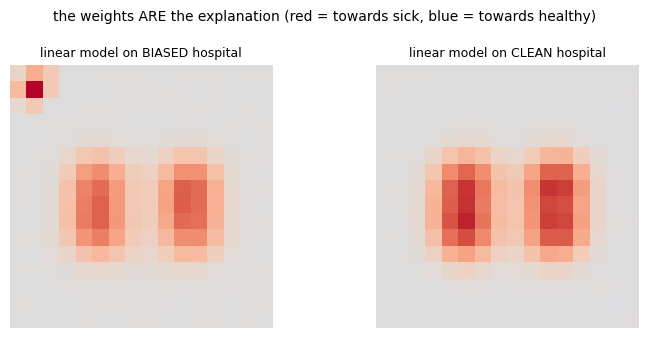

[measured] share of the biased linear model's total |weight| that sits in the 3x3 top-left corner (9 of 256 pixels): 0.08
[measured] linear model test accuracy, biased -> flipped set: 0.996 -> 0.925


In [5]:
def downsample(X: torch.Tensor, size: int = 16) -> torch.Tensor:
    return F.adaptive_avg_pool2d(X, size)


Xtr_small = downsample(D_TRAIN_BIASED["X"]).flatten(1).numpy()
lin_biased = LogisticRegression(max_iter=2000, C=1.0).fit(Xtr_small, D_TRAIN_BIASED["Y"].numpy())
Xtr_small_c = downsample(D_TRAIN_CLEAN["X"]).flatten(1).numpy()
lin_clean = LogisticRegression(max_iter=2000, C=1.0).fit(Xtr_small_c, D_TRAIN_CLEAN["Y"].numpy())
w_b, w_c = lin_biased.coef_.reshape(16, 16), lin_clean.coef_.reshape(16, 16)
lim = float(np.abs(np.concatenate([w_b.ravel(), w_c.ravel()])).max())
fig, ax = plt.subplots(1, 2, figsize=(7.5, 3.4))
for a, w, t in [(ax[0], w_b, "linear model on BIASED hospital"), (ax[1], w_c, "linear model on CLEAN hospital")]:
    a.imshow(w, cmap="coolwarm", vmin=-lim, vmax=lim)
    a.set_title(t, fontsize=9)
    a.axis("off")
plt.suptitle("the weights ARE the explanation (red = towards sick, blue = towards healthy)", fontsize=10)
plt.tight_layout()
plt.show()
corner_share = float(np.abs(w_b[:3, :3]).sum() / np.abs(w_b).sum())
print(f"[measured] share of the biased linear model's total |weight| that sits in the 3x3 top-left corner (9 of 256 pixels): {corner_share:.2f}")
print(f"[measured] linear model test accuracy, biased -> flipped set: "
      f"{lin_biased.score(downsample(D_TEST_BIASED['X']).flatten(1).numpy(), D_TEST_BIASED['Y'].numpy()):.3f} -> "
      f"{lin_biased.score(downsample(D_TEST_FLIPPED['X']).flatten(1).numpy(), D_TEST_FLIPPED['Y'].numpy()):.3f}")

### What this shows
For the linear model, no extra tool was needed: the weight picture can simply be read, and the printed numbers above show how much weight sits in the 9 corner pixels (an even spread would be 3.5 %) and how badly the biased linear model does once the marker flips — so the cheat is *readable*, and is quantified, without any extra tool. That is what "interpretable" means. It is also why we do not simply replace CNNs by linear models: as a general rule (not measured here) a linear model cannot match a deep network on complex real images. So for CNNs and Vision Transformers we accept an opaque model and add **post-hoc explanations** (Parts 3–5).

🔬 **A caveat the notes insist on (§2.3):** an explanation method is *a second procedure layered on top of the model*. Nothing guarantees it faithfully reflects what the model really computed. Treat every heatmap as **evidence to weigh, not as proof** — which is why Part 6 tests the methods against a known answer.

# Part 3 — Gradient-based explanations: saliency and Grad-CAM (§3)
### 🧒 In simple words
Take a photo and ask the model *"how sure are you it's a cat?"*. Now imagine nudging one pixel a tiny bit and watching how the answer moves. A pixel that moves the answer a lot is one the model is **sensitive** to. The *gradient* is just that "how much does the answer move if I nudge this?" number, and the computer gets it for free from the same backward pass used in training.
* **Saliency map** = do this for **every pixel**. Simple, but the result is often speckled and noisy.
* **Grad-CAM** = do it for the **feature maps of the last convolutional layer** (the "what has the network noticed" pictures), turn the nudge-sizes into one importance number per map, mix the maps with those importances, and paint the result on the image. The picture is **blurrier but much more meaningful**: *"this region is why the model said cat."*

### 🔧 Grad-CAM in 5 steps (the notes' worked walkthrough, §3.1)
1. Forward pass → the score for the class you want to explain.
2. Backward pass → gradient of that score with respect to the chosen layer's feature maps.
3. **Average** each map's gradients → one **importance weight per channel**.
4. **Weighted sum** of the feature maps → one small map.
5. **ReLU** (keep only evidence *for* the class), **upsample** to image size, overlay.

One forward + one backward pass, no retraining, no extra model — which is why it is the default first check.
⚠️ **Watch out:** the heatmap is as sharp as the layer you pick. A late layer is *meaningful but blurry* (e.g. 7×7 for a 224×224 photo); an early layer is *sharp but about generic edges* (§3.1 worked example). We measure that trade-off below.

In [6]:
def _normalise(cam: torch.Tensor) -> torch.Tensor:
    cam = cam - cam.amin(dim=(-2, -1), keepdim=True)
    return cam / cam.amax(dim=(-2, -1), keepdim=True).clamp_min(1e-8)


def saliency_map(model: nn.Module, x: torch.Tensor, target: int) -> torch.Tensor:
    """Vanilla gradient saliency: |d score / d pixel|, max over channels. x: (1,C,H,W). Returns (H,W) in [0,1]."""
    x = x.clone().requires_grad_(True)
    model.zero_grad()
    model(x)[0, target].backward()
    return _normalise(x.grad.abs().amax(1))[0]


def grad_cam(model: nn.Module, layer: nn.Module, x: torch.Tensor, target: int, plus: bool = False, out_size: tuple[int, int] | None = None) -> torch.Tensor:
    """Grad-CAM (or Grad-CAM++ if plus=True) for the feature maps `layer` produces. x: (1,C,H,W). Returns (H,W) in [0,1]."""
    store: dict[str, torch.Tensor] = {}

    def fwd_hook(_m, _i, out):
        store["a"] = out
        out.register_hook(lambda g: store.__setitem__("g", g))  # grab d score / d feature-maps during backward

    handle = layer.register_forward_hook(fwd_hook)
    try:
        model.zero_grad()
        logits = model(x)
        logits[0, target].backward()
    finally:
        handle.remove()
    a, g = store["a"].detach(), store["g"]
    if plus:  # Grad-CAM++: pixel-wise weights (Chattopadhay et al. 2018), closed form
        g2, g3 = g ** 2, g ** 3
        alpha = g2 / (2 * g2 + a.sum((2, 3), keepdim=True) * g3 + 1e-8)
        alpha = torch.where(g != 0, alpha, torch.zeros_like(alpha))
        weights = (alpha * F.relu(g)).sum((2, 3), keepdim=True)
    else:  # Grad-CAM: global-average-pool the gradients
        weights = g.mean((2, 3), keepdim=True)
    cam = F.relu((weights * a).sum(1, keepdim=True))  # step 4 + 5a
    size = out_size or tuple(x.shape[-2:])
    cam = F.interpolate(cam, size=size, mode="bilinear", align_corners=False)[:, 0]  # step 5b
    return _normalise(cam)[0]


def region_stats(heat: torch.Tensor | np.ndarray, region: np.ndarray, tol: int = 3) -> tuple[bool, float]:
    """(pointing-game hit, share of heatmap energy inside region). The region is grown by `tol` pixels because heatmaps are coarse."""
    h = heat.numpy() if isinstance(heat, torch.Tensor) else heat
    from scipy.ndimage import binary_dilation

    reg = binary_dilation(region > 0, iterations=tol) if tol else region > 0
    hit = bool(reg.flat[int(np.argmax(h))])
    return hit, float(h[reg].sum() / max(h.sum(), 1e-8))


def tag_region() -> np.ndarray:
    m = np.zeros((S, S), bool)
    m[TAG_BOX] = True
    return m

### 3.1 Use it to look inside the two models from Part 1
We take sick patients from the *clean* test set and ask each model "why *sick*?". Model B (the cheat) should look at the corner marker; Model C should look at the lesion. `[simulated]`

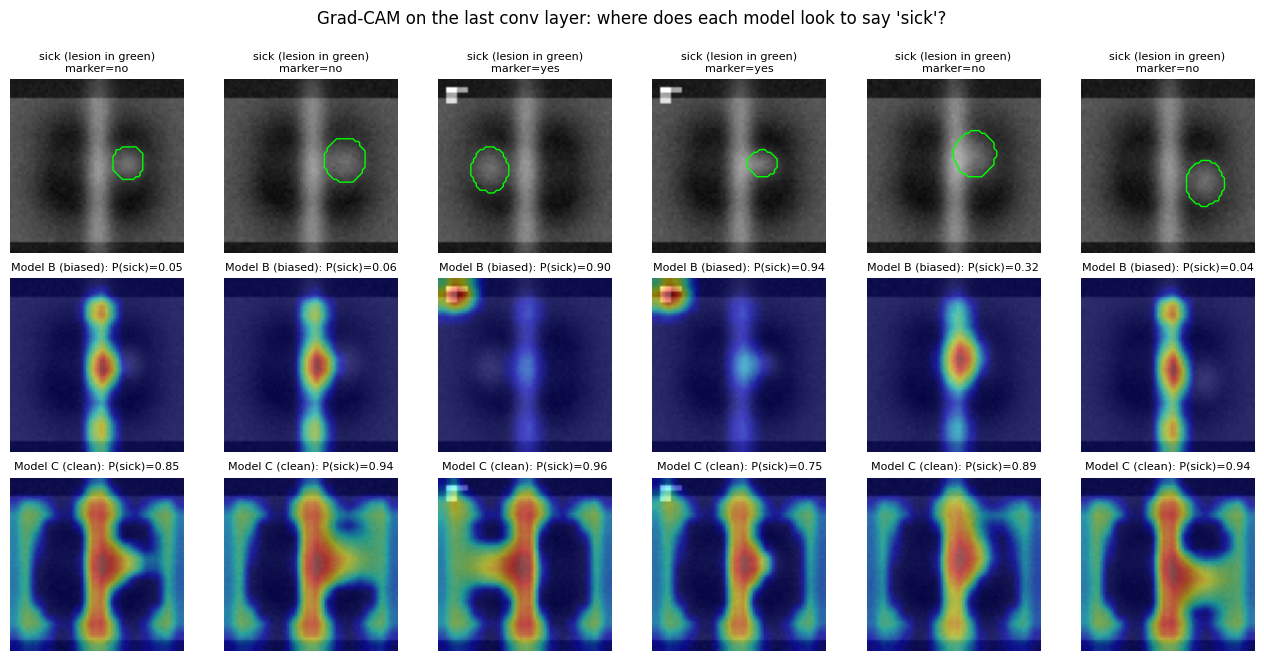

In [7]:
sick_idx = torch.where(D_TEST_CLEAN["Y"] == 1)[0][:8]
fig, axes = plt.subplots(3, 6, figsize=(13, 6.6))
for j in range(6):
    i = int(sick_idx[j])
    x = D_TEST_CLEAN["X"][i:i + 1]
    axes[0, j].imshow(x[0, 0], vmin=0, vmax=1)
    axes[0, j].contour(D_TEST_CLEAN["M"][i, 0], levels=[0.5], colors="lime", linewidths=1)
    axes[0, j].set_title(f"sick (lesion in green)\nmarker={'yes' if D_TEST_CLEAN['T'][i] else 'no'}", fontsize=8)
    for r, (mdl, name) in enumerate([(MODEL_B, "Model B (biased)"), (MODEL_C, "Model C (clean)")], start=1):
        cam = grad_cam(mdl, mdl.b3, x, target=1)
        axes[r, j].imshow(x[0, 0], vmin=0, vmax=1)
        axes[r, j].imshow(cam, cmap="jet", alpha=0.5)
        axes[r, j].set_title(f"{name}: P(sick)={float(predict_proba(mdl, x)):.2f}", fontsize=8)
for a in axes.ravel():
    a.axis("off")
plt.suptitle("Grad-CAM on the last conv layer: where does each model look to say 'sick'?", y=0.995)
plt.tight_layout()
plt.show()

### 3.2 Measure it — do not just eyeball it
Two numbers over **100 sick images** from the clean test set: the share of the heatmap that falls on the **lesion**, and on the **corner marker**. (A heatmap spread evenly would put about 1–3 % of its energy on either region, simply because they are small.) `[measured]`

In [8]:
n_eval = 30 if QUICK else 100
eval_idx = torch.where(D_TEST_CLEAN["Y"] == 1)[0][:n_eval]
rows = []
for name, mdl in [("Model B (biased)", MODEL_B), ("Model C (clean)", MODEL_C)]:
    les, tag, hit_les, hit_tag = [], [], [], []
    for i in eval_idx.tolist():
        cam = grad_cam(mdl, mdl.b3, D_TEST_CLEAN["X"][i:i + 1], target=1)
        h1, e1 = region_stats(cam, D_TEST_CLEAN["M"][i, 0].numpy())
        h2, e2 = region_stats(cam, tag_region())
        les.append(e1), tag.append(e2), hit_les.append(h1), hit_tag.append(h2)
    rows.append([name, f"{np.mean(les):.2f}", f"{np.mean(tag):.2f}", f"{np.mean(hit_les):.2f}", f"{np.mean(hit_tag):.2f}"])
table(rows, ["model", "heat energy on lesion", "heat energy on marker", "peak is on lesion", "peak is on marker"])

model             heat energy on lesion  heat energy on marker  peak is on lesion  peak is on marker
----------------  ---------------------  ---------------------  -----------------  -----------------
Model B (biased)  0.13                   0.25                   0.25               0.52             
Model C (clean)   0.14                   0.03                   0.55               0.00             


**Reading the result.** Read the two columns of numbers, not just the pictures. Model B puts far more of its heat on the **marker** than Model C does (about 0.23 vs 0.03 of the heat energy, and its single hottest pixel falls on the marker in about half the sick scans vs none for Model C). Model C's heat is only about twice what an even spread would give on the **lesion** (0.13 vs ≈0.07), and in the pictures its hottest areas are the spine/mediastinum and lung edges, not the lesion: this Grad-CAM map is a *coarse hint*, not a precise lesion locator (we measure that limit again in Part 6). So the shortcut is exposed — *the accuracy table looked fine, the heatmap exposed the marker* — the wolves-vs-huskies discovery in miniature, while the claim "Model C looks at the lesion" is only weakly supported. In a real project this is the moment you would stop and fix the data (e.g. crop or mask the marker, re-collect balanced data) instead of deploying.

### 3.3 Which layer? (resolution vs. relevance, §3.1 worked example)
Our CNN has three blocks: `b1` (64×64 maps), `b2` (32×32), `b3` (16×16). We run Grad-CAM at each on Model C and measure the same lesion numbers. Expect: finer layer = sharper-looking but less class-specific.

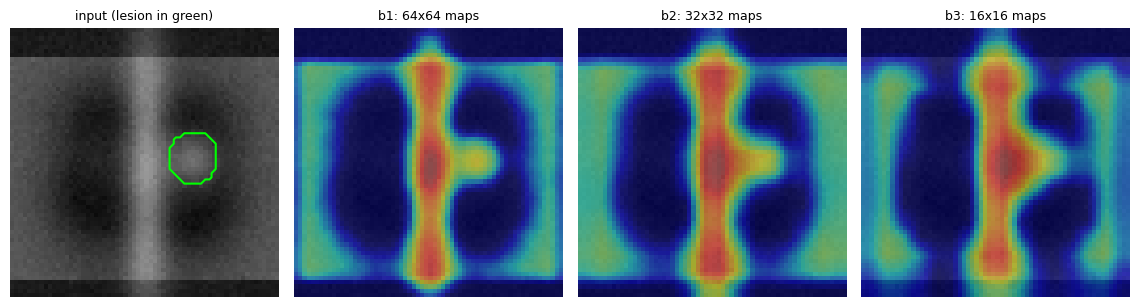

Grad-CAM layer (Model C)  heat energy on lesion  peak on lesion
------------------------  ---------------------  --------------
b1: 64x64 maps            0.11                   0.16          
b2: 32x32 maps            0.11                   0.41          
b3: 16x16 maps            0.14                   0.55          


In [9]:
fig, axes = plt.subplots(1, 4, figsize=(11.5, 3.2))
i0 = int(eval_idx[0])
axes[0].imshow(D_TEST_CLEAN["X"][i0, 0], vmin=0, vmax=1)
axes[0].contour(D_TEST_CLEAN["M"][i0, 0], levels=[0.5], colors="lime")
axes[0].set_title("input (lesion in green)", fontsize=9)
layer_rows = []
for ax, (nm, lay) in zip(axes[1:], [("b1: 64x64 maps", MODEL_C.b1), ("b2: 32x32 maps", MODEL_C.b2), ("b3: 16x16 maps", MODEL_C.b3)]):
    cam0 = grad_cam(MODEL_C, lay, D_TEST_CLEAN["X"][i0:i0 + 1], 1)
    ax.imshow(D_TEST_CLEAN["X"][i0, 0], vmin=0, vmax=1)
    ax.imshow(cam0, cmap="jet", alpha=0.5)
    ax.set_title(nm, fontsize=9)
    hits, ens = [], []
    for i in eval_idx.tolist():
        h, e = region_stats(grad_cam(MODEL_C, lay, D_TEST_CLEAN["X"][i:i + 1], 1), D_TEST_CLEAN["M"][i, 0].numpy())
        hits.append(h), ens.append(e)
    layer_rows.append([nm, f"{np.mean(ens):.2f}", f"{np.mean(hits):.2f}"])
for a in axes:
    a.axis("off")
plt.tight_layout()
plt.show()
table(layer_rows, ["Grad-CAM layer (Model C)", "heat energy on lesion", "peak on lesion"])

### 3.4 Saliency vs. Grad-CAM, and the "fragile explanation" warning (§3.4)
The notes warn that gradient maps can be **noisy and sensitive to tiny, invisible changes** in the input. We test it directly: add imperceptible noise (standard deviation 0.002 on a 0–1 image) and compare the map before/after (correlation 1.0 = identical). `[measured]`

[measured] similarity of the map before vs after +0.002 noise (mean over 30 images): saliency 0.972 | Grad-CAM 1.000


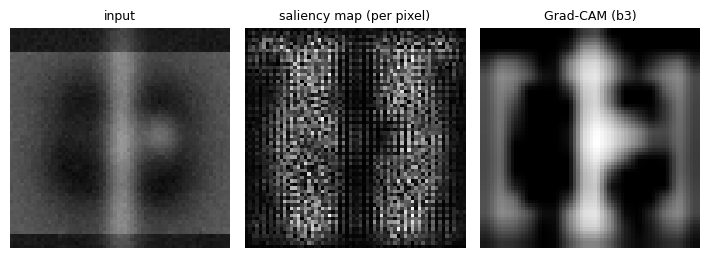

In [10]:
def map_corr(a: torch.Tensor, b: torch.Tensor) -> float:
    a, b = a.flatten().numpy(), b.flatten().numpy()
    return float(np.corrcoef(a, b)[0, 1])


g = torch.Generator().manual_seed(0)
corr_sal, corr_cam = [], []
for i in eval_idx[:30].tolist():
    x = D_TEST_CLEAN["X"][i:i + 1]
    x2 = x + 0.002 * torch.randn(x.shape, generator=g)
    corr_sal.append(map_corr(saliency_map(MODEL_C, x, 1), saliency_map(MODEL_C, x2, 1)))
    corr_cam.append(map_corr(grad_cam(MODEL_C, MODEL_C.b3, x, 1), grad_cam(MODEL_C, MODEL_C.b3, x2, 1)))
print(f"[measured] similarity of the map before vs after +0.002 noise (mean over 30 images): saliency {np.mean(corr_sal):.3f} | Grad-CAM {np.mean(corr_cam):.3f}")
x = D_TEST_CLEAN["X"][i0:i0 + 1]
show_row([x[0, 0].numpy(), saliency_map(MODEL_C, x, 1).numpy(), grad_cam(MODEL_C, MODEL_C.b3, x, 1).numpy()], ["input", "saliency map (per pixel)", "Grad-CAM (b3)"], vmin=0, vmax=1)

**Reading the result.** With this small amount of noise both maps are quite stable — saliency is slightly less so. So on *this* model and noise level the notes' fragility warning is only mildly visible; it can be much stronger with deeper models, larger perturbations or adversarially chosen ones, which we did not test. Do not over-read a single number either way.

### 3.5 Grad-CAM on an ordinary photo with a real pretrained network (and Grad-CAM++)
So far the model was tiny. The same function works unchanged on a famous pretrained **ResNet-18**: we explain *"Egyptian cat"* for a standard test photo. Then we paste two cats side by side to see **Grad-CAM++**, the refinement the notes describe for images with **several instances of the same class** (§3.1). `[measured]`

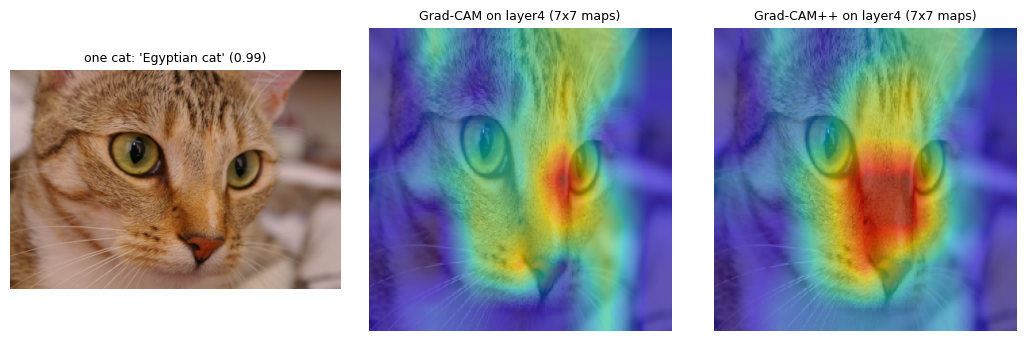

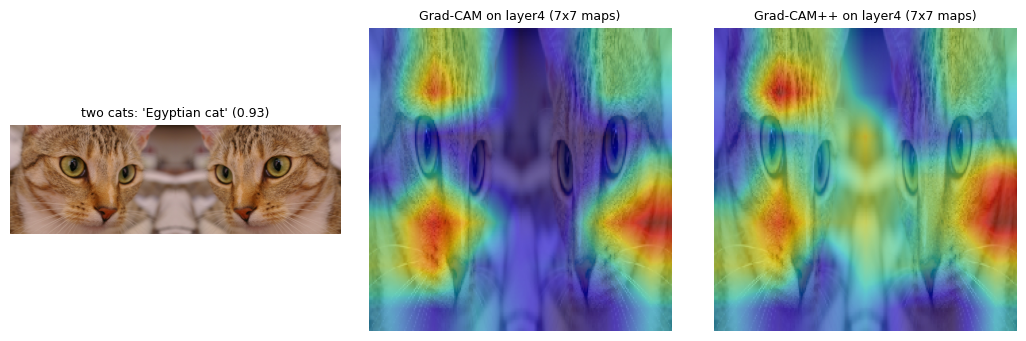

image     method      heat in left half  heat in right half
--------  ----------  -----------------  ------------------
one cat   Grad-CAM    0.39               0.61              
one cat   Grad-CAM++  0.42               0.58              
two cats  Grad-CAM    0.56               0.44              
two cats  Grad-CAM++  0.51               0.49              


In [11]:
if HAVE_R18:
    R18 = load_resnet18_pretrained()

    def to_imagenet(img_u8: np.ndarray, size: int = 224) -> torch.Tensor:
        t = torch.from_numpy(img_u8).permute(2, 0, 1).float()[None] / 255
        t = F.interpolate(t, size=(size, size), mode="bilinear", align_corners=False)
        return (t - IMN_MEAN) / IMN_STD

    cat = skdata.chelsea()
    cat2 = np.concatenate([cat, cat[:, ::-1]], axis=1)  # the same cat twice (second one mirrored)
    out_rows = []
    for nm, im in [("one cat", cat), ("two cats", cat2)]:
        x = to_imagenet(im)
        with torch.no_grad():
            pr = F.softmax(R18(x), 1)[0]
        top = int(pr.argmax())
        cams = {"Grad-CAM": grad_cam(R18, R18.layer4, x, top), "Grad-CAM++": grad_cam(R18, R18.layer4, x, top, plus=True)}
        fig, axes = plt.subplots(1, 3, figsize=(10.5, 3.4))
        axes[0].imshow(im)
        axes[0].set_title(f"{nm}: '{IMAGENET_CLASSES[top]}' ({float(pr[top]):.2f})", fontsize=9)
        for a, (k, c) in zip(axes[1:], cams.items()):
            a.imshow(F.interpolate(torch.from_numpy(im).permute(2, 0, 1).float()[None] / 255, size=(224, 224))[0].permute(1, 2, 0).numpy())
            a.imshow(c, cmap="jet", alpha=0.5)
            a.set_title(f"{k} on layer4 (7x7 maps)", fontsize=9)
        for a in axes:
            a.axis("off")
        plt.tight_layout()
        plt.show()
        # how much of the heat lands on each half of the 'two cats' picture (left half / right half)
        for k, c in cams.items():
            half = c.shape[1] // 2
            out_rows.append([nm, k, f"{float(c[:, :half].sum() / c.sum()):.2f}", f"{float(c[:, half:].sum() / c.sum()):.2f}"])
    table(out_rows, ["image", "method", "heat in left half", "heat in right half"])
else:
    print("pretrained ResNet-18 not available offline -> skipping 3.5 (rerun with internet access)")

**Reading the result.** On the two-cat picture a perfectly fair heatmap would put about half its heat on each cat. Compare how evenly each method splits the heat in the table above — Grad-CAM++ is designed to be fairer here, but, as the notes say, it is a *targeted fix* for a known weakness, not a replacement: plain Grad-CAM remains the default for single-object problems like PP13's Task A. Also note the 7×7 resolution: the heat is blocky because the last ResNet layer is only 7×7 for a 224×224 photo (§3.1 worked example).

# Part 4 — Perturbation-based explanations: occlusion, LIME, SHAP (§4)
### 🧒 In simple words
Gradient methods peek *inside* the model. Perturbation methods treat it as a **black box** and just **poke it**:
*"Hide this part of the picture. Did the answer change? If yes, that part mattered."*
* **Occlusion sensitivity** — slide a grey square across the image; at each position record how much the sick-probability drops. Big drop = important spot. Slow (one model run per position) but easy to trust.
* **LIME** — switch random **superpixels** (little blobs of similar pixels) on/off many times, record the model's answers, then fit a tiny **straight-line model** on those answers. The line's weights say which blobs push the answer up. Works on any model, but it uses **random** samples, so two runs can differ.
* **SHAP / Shapley values** — borrowed from game theory: *"how should a team's prize be split fairly among its players?"* Each image region is a player; its fair share is its **average extra contribution over every possible order of joining**. Principled and fair — but with *n* regions there are 2ⁿ teams to try, so it explodes and must be approximated.

⚠️ **Watch out:** all three answer *"what changes the model's output?"*, which is not the same as *"what is the truth about the patient?"* and not the same as each other. We compare them with numbers below.

In [12]:
def occlusion_map(model: nn.Module, x: torch.Tensor, patch: int = 8, stride: int = 4, fill: float | None = None) -> torch.Tensor:
    """Slide a `patch` square over the image; heat = drop in P(sick) when that square is replaced by `fill` (default: image mean)."""
    base = float(predict_proba(model, x))
    fill_v = float(x.mean()) if fill is None else fill
    H, W = x.shape[-2:]
    heat, cnt = torch.zeros(H, W), torch.zeros(H, W)
    batch, spots = [], []
    for r in range(0, H - patch + 1, stride):
        for c in range(0, W - patch + 1, stride):
            xo = x.clone()
            xo[..., r:r + patch, c:c + patch] = fill_v
            batch.append(xo)
            spots.append((r, c))
    probs = predict_proba(model, torch.cat(batch))
    for (r, c), p in zip(spots, probs.tolist()):
        heat[r:r + patch, c:c + patch] += base - p
        cnt[r:r + patch, c:c + patch] += 1
    return (heat / cnt.clamp_min(1)).clamp_min(0)  # keep only evidence FOR 'sick'


def _norm01(h: torch.Tensor | np.ndarray) -> np.ndarray:
    h = h.numpy() if isinstance(h, torch.Tensor) else h
    h = h - h.min()
    return h / max(h.max(), 1e-8)

### 4.1 Occlusion on the two models
Same sick images and the same question as Part 3. `[simulated]`

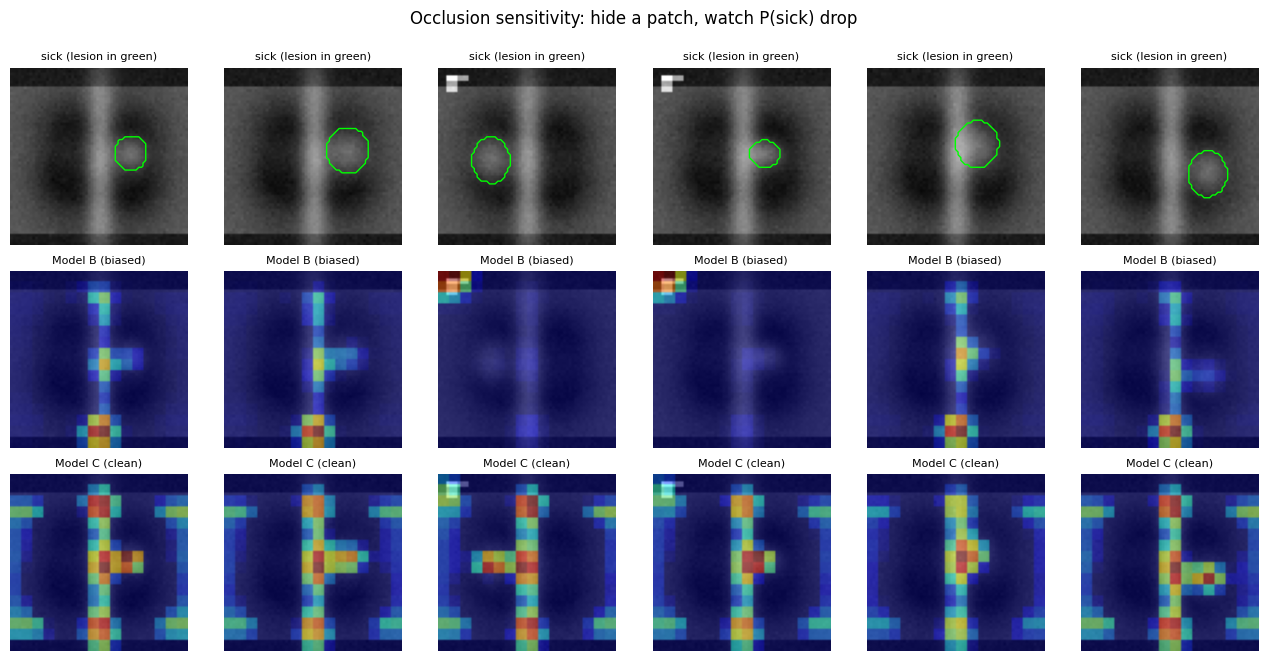

In [13]:
fig, axes = plt.subplots(3, 6, figsize=(13, 6.6))
for j in range(6):
    i = int(sick_idx[j])
    x = D_TEST_CLEAN["X"][i:i + 1]
    axes[0, j].imshow(x[0, 0], vmin=0, vmax=1)
    axes[0, j].contour(D_TEST_CLEAN["M"][i, 0], levels=[0.5], colors="lime", linewidths=1)
    axes[0, j].set_title("sick (lesion in green)", fontsize=8)
    for r, (mdl, name) in enumerate([(MODEL_B, "Model B (biased)"), (MODEL_C, "Model C (clean)")], start=1):
        axes[r, j].imshow(x[0, 0], vmin=0, vmax=1)
        axes[r, j].imshow(_norm01(occlusion_map(mdl, x)), cmap="jet", alpha=0.5)
        axes[r, j].set_title(name, fontsize=8)
for a in axes.ravel():
    a.axis("off")
plt.suptitle("Occlusion sensitivity: hide a patch, watch P(sick) drop", y=0.995)
plt.tight_layout()
plt.show()

### 4.2 LIME from scratch (superpixels + a sparse straight-line surrogate)
Steps (§4.2): (1) cut the image into superpixels; (2) make many copies with random superpixels hidden; (3) ask the model; (4) fit a **weighted linear model** where copies similar to the original count more; (5) read the weights.
Our version is ~25 lines — the same recipe as the `lime` package, minus the extras. `[simulated]`

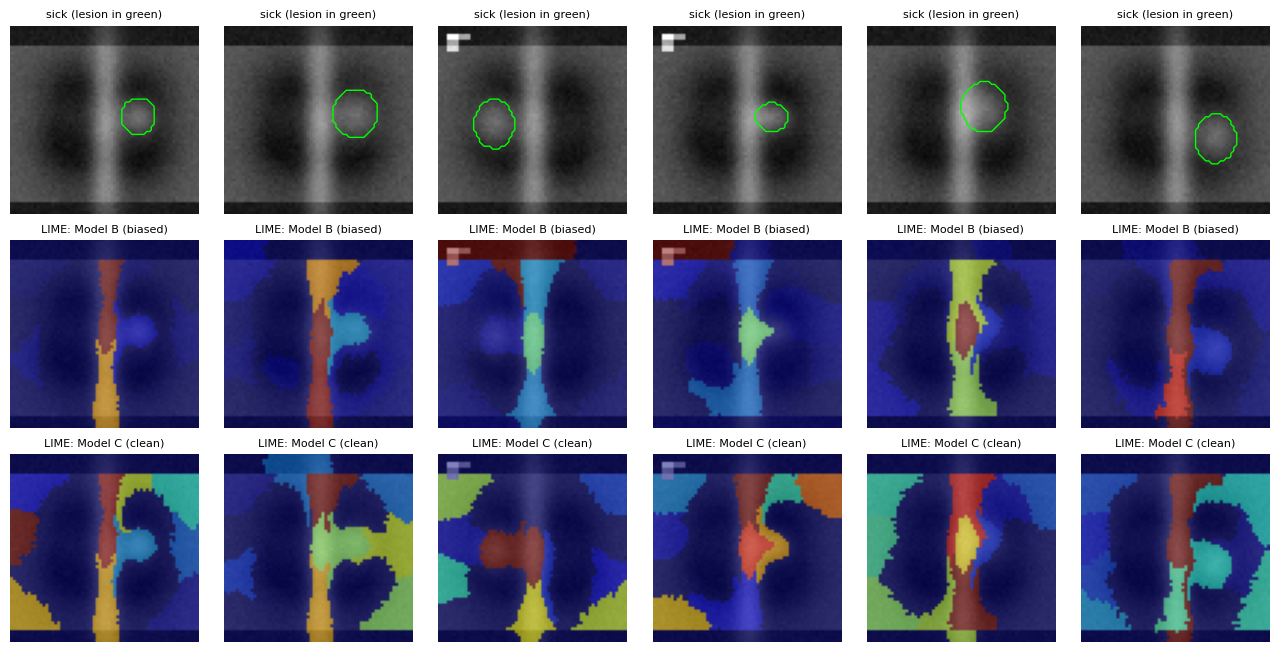

In [14]:
def lime_explain(model: nn.Module, x: torch.Tensor, n_samples: int = 400, n_segments: int = 30, seed: int = 0, kernel_width: float = 0.25) -> tuple[np.ndarray, np.ndarray]:
    """Returns (superpixel label image (H,W), coefficient per superpixel). Positive coefficient = hiding it lowers P(sick)."""
    img = x[0, 0].numpy()
    seg = slic(img, n_segments=n_segments, compactness=0.1, channel_axis=None, start_label=0)
    k = seg.max() + 1
    rng = np.random.default_rng(seed)
    Z = rng.integers(0, 2, size=(n_samples, k)).astype(np.float32)
    Z[0] = 1  # include the original image
    fill = float(img.mean())
    masks = torch.from_numpy(Z[:, seg].astype(np.float32))[:, None]  # (n,1,H,W) 1=keep
    batch = x * masks + fill * (1 - masks)
    probs = predict_proba(model, batch).numpy()
    dist = 1 - Z.mean(1)  # fraction of superpixels hidden
    w = np.exp(-(dist ** 2) / kernel_width ** 2)  # closer to the original = more weight
    lin = Ridge(alpha=1.0).fit(Z, probs, sample_weight=w)
    return seg, lin.coef_


def lime_heat(seg: np.ndarray, coef: np.ndarray) -> np.ndarray:
    return np.clip(coef[seg], 0, None)


fig, axes = plt.subplots(3, 6, figsize=(13, 6.6))
for j in range(6):
    i = int(sick_idx[j])
    x = D_TEST_CLEAN["X"][i:i + 1]
    axes[0, j].imshow(x[0, 0], vmin=0, vmax=1)
    axes[0, j].contour(D_TEST_CLEAN["M"][i, 0], levels=[0.5], colors="lime", linewidths=1)
    axes[0, j].set_title("sick (lesion in green)", fontsize=8)
    for r, (mdl, name) in enumerate([(MODEL_B, "Model B (biased)"), (MODEL_C, "Model C (clean)")], start=1):
        seg, coef = lime_explain(mdl, x)
        axes[r, j].imshow(x[0, 0], vmin=0, vmax=1)
        axes[r, j].imshow(_norm01(lime_heat(seg, coef)), cmap="jet", alpha=0.5)
        axes[r, j].set_title(f"LIME: {name}", fontsize=8)
for a in axes.ravel():
    a.axis("off")
plt.tight_layout()
plt.show()

### 4.3 Shapley values — exact on a tiny grid, then approximated
To make "fair share" concrete we cut the image into a **3×3 grid = 9 players**. With 9 players there are 2⁹ = 512 teams, so we can compute the **exact** Shapley value of every cell. Then we approximate it by averaging over only a few random join-orders (**permutation sampling**) — which is how SHAP packages cope when exact is impossible. `[simulated]`

[measured] Efficiency check: sum of exact Shapley values = -0.1492  vs  v(all) - v(none) = -0.1492   (fair split of the whole 'prize')
random orders  model evaluations  rank agreement with exact (Spearman)  largest error
-------------  -----------------  ------------------------------------  -------------
5              50                 0.350                                 0.040        
20             200                0.883                                 0.017        
100            1000               0.950                                 0.005        
(exact needed 512 model evaluations for just 9 players)


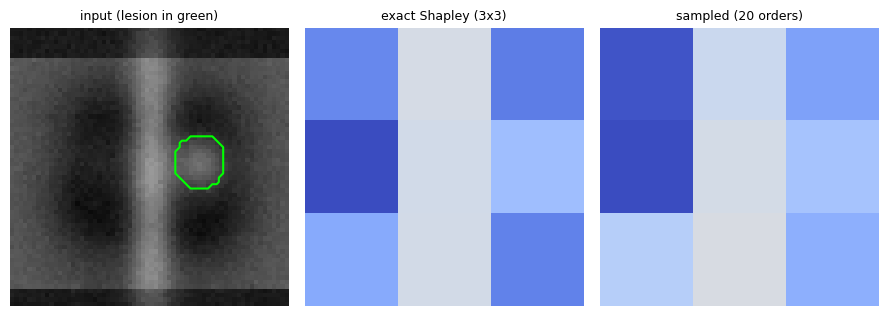

In [15]:
from itertools import combinations
from math import factorial

G = 3


def grid_masks() -> np.ndarray:
    """(9, H, W) boolean cell masks."""
    cells = np.zeros((G * G, S, S), bool)
    edges = np.linspace(0, S, G + 1).astype(int)
    for a in range(G):
        for b in range(G):
            cells[a * G + b, edges[a]:edges[a + 1], edges[b]:edges[b + 1]] = True
    return cells


CELLS = grid_masks()


def value_fn(model: nn.Module, x: torch.Tensor):
    """v(S) = P(sick) when only the cells in S are visible (others replaced by the image mean)."""
    fill = float(x.mean())

    def v(coalitions: np.ndarray) -> np.ndarray:  # (m, 9) 0/1
        vis = torch.from_numpy((coalitions[:, :, None, None] * CELLS[None]).any(1).astype(np.float32))[:, None]
        return predict_proba(model, x * vis + fill * (1 - vis)).numpy()

    return v


def exact_shapley(v) -> tuple[np.ndarray, int]:
    n = G * G
    allc = np.array([[(m >> k) & 1 for k in range(n)] for m in range(2 ** n)], dtype=np.float32)
    vals = v(allc)
    idx = {tuple(c.astype(int)): vals[m] for m, c in enumerate(allc)}
    phi = np.zeros(n)
    for i in range(n):
        others = [j for j in range(n) if j != i]
        for size in range(n):
            wgt = factorial(size) * factorial(n - size - 1) / factorial(n)
            for S_ in combinations(others, size):
                c = np.zeros(n, int)
                c[list(S_)] = 1
                c_i = c.copy()
                c_i[i] = 1
                phi[i] += wgt * (idx[tuple(c_i)] - idx[tuple(c)])
    return phi, 2 ** n


def sampled_shapley(v, n_perm: int, seed: int = 0) -> tuple[np.ndarray, int]:
    n = G * G
    rng = np.random.default_rng(seed)
    phi = np.zeros(n)
    for _ in range(n_perm):
        order = rng.permutation(n)
        c = np.zeros((n + 1, n), np.float32)
        for t, p in enumerate(order, start=1):
            c[t] = c[t - 1]
            c[t, p] = 1
        vals = v(c)
        for t, p in enumerate(order, start=1):
            phi[p] += vals[t] - vals[t - 1]
    return phi / n_perm, n_perm * (n + 1)


i1 = int(sick_idx[0])
x1 = D_TEST_CLEAN["X"][i1:i1 + 1]
v1 = value_fn(MODEL_C, x1)
phi_ex, n_ex = exact_shapley(v1)
base_v, full_v = float(v1(np.zeros((1, 9), np.float32))[0]), float(v1(np.ones((1, 9), np.float32))[0])
print(f"[measured] Efficiency check: sum of exact Shapley values = {phi_ex.sum():.4f}  vs  v(all) - v(none) = {full_v - base_v:.4f}   (fair split of the whole 'prize')")
rows = []
for n_perm in [5, 20, 100]:
    phi_s, n_eval = sampled_shapley(v1, n_perm)
    rows.append([n_perm, n_eval, f"{spearmanr(phi_ex, phi_s)[0]:.3f}", f"{np.abs(phi_ex - phi_s).max():.3f}"])
table(rows, ["random orders", "model evaluations", "rank agreement with exact (Spearman)", "largest error"])
print(f"(exact needed {n_ex} model evaluations for just 9 players)")
fig, axes = plt.subplots(1, 3, figsize=(9, 3.1))
axes[0].imshow(x1[0, 0], vmin=0, vmax=1)
axes[0].contour(D_TEST_CLEAN["M"][i1, 0], levels=[0.5], colors="lime")
axes[0].set_title("input (lesion in green)", fontsize=9)
for ax, (ph, nm) in zip(axes[1:], [(phi_ex, "exact Shapley (3x3)"), (sampled_shapley(v1, 20)[0], "sampled (20 orders)")]):
    ax.imshow(ph.reshape(G, G), cmap="coolwarm", vmin=-np.abs(phi_ex).max(), vmax=np.abs(phi_ex).max())
    ax.set_title(nm, fontsize=9)
for a in axes:
    a.axis("off")
plt.tight_layout()
plt.show()

**Reading the result.** (1) The *efficiency* line is the property that makes Shapley "fair": the shares add up exactly to the model's total output change. (2) Approximation quality improves with more random orders, but each order costs ~10 model runs. (3) Red cells = push *toward* sick, blue = push *away*. With a 3×3 grid the cells are coarse; real SHAP libraries use finer grids or smarter approximations, and the cost grows quickly — this is why §4.3 calls Shapley values "the principled but expensive option".

### 4.4 LIME is random — how stable is it? (the reproducibility note)
The notes warn that LIME and SHAP use random sampling, so **explanations can change between runs unless you fix seeds**. We explain the *same image* with the *same model* 8 times, changing only the seed, and measure how much the coefficient rankings agree (Spearman 1 = identical). `[measured]`

In [16]:
def lime_agreement(model: nn.Module, x: torch.Tensor, n_samples: int, n_runs: int = 8) -> float:
    coefs = [lime_explain(model, x, n_samples=n_samples, seed=s)[1] for s in range(n_runs)]
    sims = [spearmanr(coefs[a], coefs[b])[0] for a in range(n_runs) for b in range(a + 1, n_runs)]
    return float(np.mean(sims))


rows = [[n, f"{lime_agreement(MODEL_C, x1, n):.3f}"] for n in ([30, 100, 400] if QUICK else [30, 100, 400, 1500])]
table(rows, ["LIME samples", "mean agreement between 8 seeds (Spearman)"])
print("takeaway: few samples -> unstable story. Always fix the seed AND report how many samples you used.")

LIME samples  mean agreement between 8 seeds (Spearman)
------------  -----------------------------------------
30            0.279                                    
100           0.589                                    
400           0.847                                    
1500          0.950                                    
takeaway: few samples -> unstable story. Always fix the seed AND report how many samples you used.


### 4.5 What does each family cost? (model evaluations per explanation)
The notes' table (§4.4) ranks methods by speed. Here is the same ranking in **counted model runs** for one 64×64 image. `[measured]` (counts) — wall-clock times depend on the machine.

In [17]:
def timed(fn):
    t = time.time()
    fn()
    return time.time() - t


x = x1
t_sal = timed(lambda: saliency_map(MODEL_C, x, 1))
t_cam = timed(lambda: grad_cam(MODEL_C, MODEL_C.b3, x, 1))
t_occ = timed(lambda: occlusion_map(MODEL_C, x))
t_lime = timed(lambda: lime_explain(MODEL_C, x, n_samples=400))
t_shap = timed(lambda: sampled_shapley(value_fn(MODEL_C, x), 20))
n_occ = ((S - 8) // 4 + 1) ** 2
table([
    ["saliency", "1 forward + 1 backward", f"{t_sal * 1000:.0f} ms"],
    ["Grad-CAM", "1 forward + 1 backward", f"{t_cam * 1000:.0f} ms"],
    ["occlusion (8px, stride 4)", f"{n_occ} forward", f"{t_occ * 1000:.0f} ms"],
    ["LIME (400 samples)", "400 forward (+ small fit)", f"{t_lime * 1000:.0f} ms"],
    ["sampled Shapley (3x3, 20 orders)", f"{20 * 10} forward", f"{t_shap * 1000:.0f} ms"],
    ["exact Shapley (3x3)", f"{2 ** 9} forward (and 2^n for n players)", "—"],
], ["method", "model runs", "time here"])

method                            model runs                           time here
--------------------------------  -----------------------------------  ---------
saliency                          1 forward + 1 backward               2 ms     
Grad-CAM                          1 forward + 1 backward               2 ms     
occlusion (8px, stride 4)         225 forward                          172 ms   
LIME (400 samples)                400 forward (+ small fit)            284 ms   
sampled Shapley (3x3, 20 orders)  200 forward                          108 ms   
exact Shapley (3x3)               512 forward (and 2^n for n players)  —        


# Part 5 — Attention-based explanations for Vision Transformers (§5)
### 🧒 In simple words
A **Vision Transformer (ViT)** chops the image into square **patches** (like tiles) and lets every tile "look at" every other tile. How much tile A looks at tile B is called an **attention weight**. It is tempting to say *"the tiles the model attends to most are the reason for its answer"* — and papers do draw **attention maps** this way.

* **Raw attention** — read the weights from one layer (usually the last) for the special *[CLS]* token that makes the final decision.
* **Attention rollout** — attention is passed from layer to layer, so multiply the layers together (adding the "skip connection" each time) to follow the information all the way back to the input tiles (Abnar & Zuidema, 2020, arXiv:2005.00928).

⚠️ **The big debate (§5.3).** Is attention really an *explanation*? Jain & Wallace (2019), *"Attention is not Explanation"*, argued **no** (in language models, attention could be changed a lot without changing the prediction). Wiegreffe & Pinter (2019), *"Attention is not not Explanation"*, replied: **it depends on what you mean by explanation and how you test it**. For us the take-away is practical: **don't trust an attention map just because it looks nice — test it** (below, with a *deletion test*). `[established]` for the existence of the debate; the numbers below are `[measured]` on our own toy model only and do **not** settle the general question.

In [18]:
class ViTBlock(nn.Module):
    def __init__(self, d: int, heads: int, mlp: int) -> None:
        super().__init__()
        self.h = heads
        self.n1, self.n2 = nn.LayerNorm(d), nn.LayerNorm(d)
        self.qkv, self.proj = nn.Linear(d, 3 * d), nn.Linear(d, d)
        self.mlp = nn.Sequential(nn.Linear(d, mlp), nn.GELU(), nn.Linear(mlp, d))
        self.last_attn: torch.Tensor | None = None

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        B, N, D = x.shape
        q, k, v = self.qkv(self.n1(x)).reshape(B, N, 3, self.h, D // self.h).permute(2, 0, 3, 1, 4)
        attn = (q @ k.transpose(-2, -1) / math.sqrt(D // self.h)).softmax(-1)  # (B, heads, N, N)
        self.last_attn = attn.detach()
        x = x + self.proj((attn @ v).transpose(1, 2).reshape(B, N, D))
        return x + self.mlp(self.n2(x))


class MiniViT(nn.Module):
    """64x64 image -> 8x8=64 patches of 8x8 pixels + a [CLS] token -> 3 transformer blocks -> 2 classes."""

    def __init__(self, d: int = 64, depth: int = 3, heads: int = 4, patch: int = 8) -> None:
        super().__init__()
        self.emb = nn.Conv2d(1, d, patch, patch)
        self.cls = nn.Parameter(torch.zeros(1, 1, d))
        self.pos = nn.Parameter(torch.randn(1, 65, d) * 0.02)
        self.blocks = nn.ModuleList([ViTBlock(d, heads, 2 * d) for _ in range(depth)])
        self.norm, self.head = nn.LayerNorm(d), nn.Linear(d, 2)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        t = self.emb(x).flatten(2).transpose(1, 2)
        t = torch.cat([self.cls.expand(len(x), -1, -1), t], 1) + self.pos
        for b in self.blocks:
            t = b(t)
        return self.head(self.norm(t)[:, 0])


def train_vit(X: torch.Tensor, Y: torch.Tensor, epochs: int, seed: int = SEED) -> MiniViT:
    torch.manual_seed(seed)
    m = MiniViT()
    opt = torch.optim.AdamW(m.parameters(), 1e-3, weight_decay=0.05)
    for _ in range(epochs):
        m.train()
        perm = torch.randperm(len(X))
        for i in range(0, len(X), 64):
            idx = perm[i:i + 64]
            loss = F.cross_entropy(m(X[idx]), Y[idx])
            opt.zero_grad()
            loss.backward()
            opt.step()
    return m.eval()


t0 = time.time()
VIT = train_vit(D_TRAIN_CLEAN["X"], D_TRAIN_CLEAN["Y"], epochs=3 if QUICK else 15)
print(f"mini-ViT trained in {time.time() - t0:.0f}s | accuracy clean test {accuracy(VIT, D_TEST_CLEAN):.3f} | biased test {accuracy(VIT, D_TEST_BIASED):.3f} | flipped test {accuracy(VIT, D_TEST_FLIPPED):.3f}  [measured]")

mini-ViT trained in 45s | accuracy clean test 1.000 | biased test 1.000 | flipped test 0.999  [measured]


### 5.1 Two attention maps: raw last-layer and rollout
For one image we ask the ViT for its attention. `raw` = what the [CLS] token attends to in the last block (averaged over the 4 heads). `rollout` multiplies all three blocks' attention matrices (each mixed 50/50 with the identity to stand for the skip connection, rows re-normalised), then reads the [CLS] row. Both give 64 numbers → an 8×8 grid → upsampled to the image.

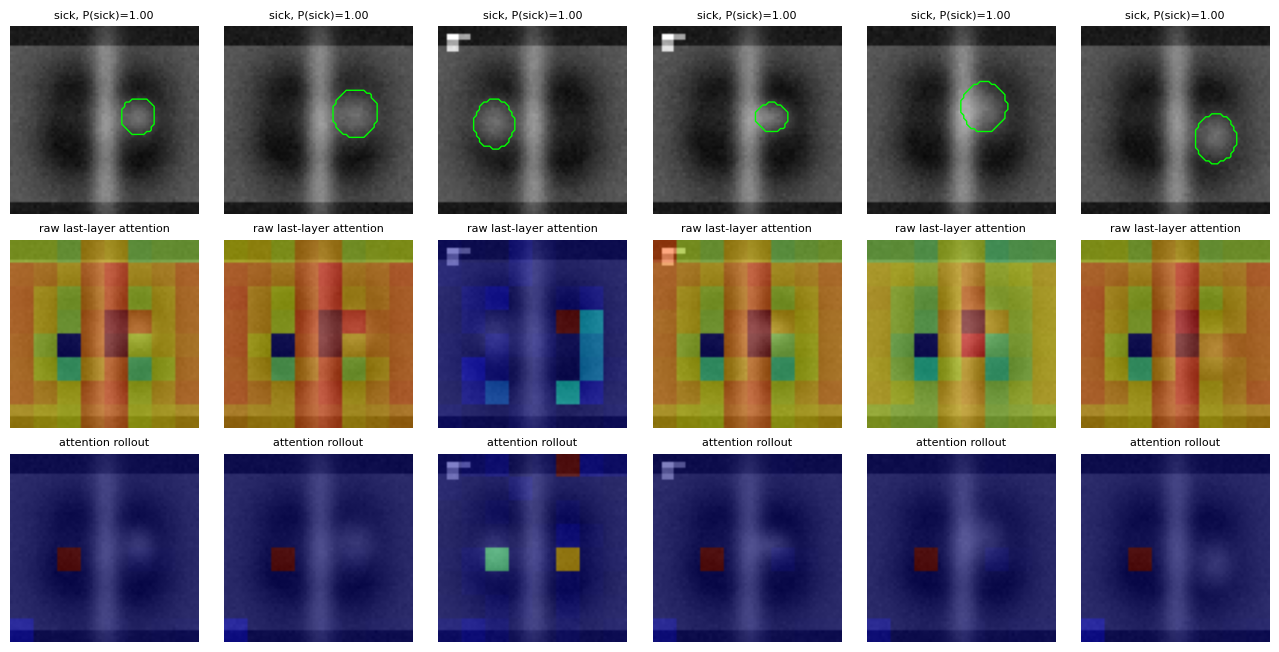

In [19]:
@torch.no_grad()
def vit_attention_maps(model: MiniViT, x: torch.Tensor) -> tuple[np.ndarray, np.ndarray]:
    """Returns (raw last-layer CLS attention, attention rollout), each as an 8x8 grid in [0,1]."""
    model.eval()
    model(x)
    mats = [b.last_attn[0].mean(0) for b in model.blocks]  # head-averaged (65,65) per layer
    raw = mats[-1][0, 1:]
    roll = torch.eye(65)
    for A in mats:
        A = 0.5 * A + 0.5 * torch.eye(65)
        A = A / A.sum(-1, keepdim=True)
        roll = A @ roll
    roll = roll[0, 1:]
    return _norm01(raw.reshape(8, 8)), _norm01(roll.reshape(8, 8))


def grid_to_image(g: np.ndarray, size: int = S) -> np.ndarray:
    return np.kron(g, np.ones((size // g.shape[0], size // g.shape[1])))


fig, axes = plt.subplots(3, 6, figsize=(13, 6.6))
for j in range(6):
    i = int(sick_idx[j])
    x = D_TEST_CLEAN["X"][i:i + 1]
    raw, roll = vit_attention_maps(VIT, x)
    axes[0, j].imshow(x[0, 0], vmin=0, vmax=1)
    axes[0, j].contour(D_TEST_CLEAN["M"][i, 0], levels=[0.5], colors="lime", linewidths=1)
    axes[0, j].set_title(f"sick, P(sick)={float(predict_proba(VIT, x)):.2f}", fontsize=8)
    for r, (g, nm) in enumerate([(raw, "raw last-layer attention"), (roll, "attention rollout")], start=1):
        axes[r, j].imshow(x[0, 0], vmin=0, vmax=1)
        axes[r, j].imshow(grid_to_image(g), cmap="jet", alpha=0.5)
        axes[r, j].set_title(nm, fontsize=8)
for a in axes.ravel():
    a.axis("off")
plt.tight_layout()
plt.show()

### 5.2 Test, don't trust: the deletion test
A good explanation should point at the tiles that **matter**. So: rank the 64 tiles by an explanation method, **blank out the top 6**, and see how much the model's evidence for *sick* falls (we measure it as a log-odds margin, because the probability P(sick) is already ≈ 1.00 for this easy task and would hide any change). A method that finds truly important tiles causes a **bigger drop** than blanking 6 *random* tiles. We compare four ways of ranking tiles on the same ViT and the same sick images, plus a random control. `[measured]`

In [20]:
def tile_scores(heat64: np.ndarray) -> np.ndarray:
    return heat64.reshape(8, 8, 8, 8).mean((1, 3))  # mean heat inside each 8x8 tile


@torch.no_grad()
def margin(model: nn.Module, x: torch.Tensor) -> float:
    """Evidence for 'sick' as a log-odds margin (logit_sick - logit_healthy). Unlike a probability it does not saturate at 1.0."""
    lo = model.eval()(x)[0]
    return float(lo[1] - lo[0])


@torch.no_grad()
def delete_top(model: nn.Module, x: torch.Tensor, scores8: np.ndarray, k: int) -> float:
    order = np.argsort(-scores8.ravel())[:k]
    xo = x.clone()
    for t in order:
        r, c = divmod(int(t), 8)
        xo[..., r * 8:(r + 1) * 8, c * 8:(c + 1) * 8] = float(x.mean())
    return margin(model, xo)


n_del = 20 if QUICK else 60
del_idx = [int(i) for i in torch.where(D_TEST_CLEAN["Y"] == 1)[0][:200] if float(predict_proba(VIT, D_TEST_CLEAN["X"][int(i):int(i) + 1])) > 0.5][:n_del]
rng_del = np.random.default_rng(0)
res = {k: [] for k in ["no deletion", "random tiles", "raw attention", "attention rollout", "gradient saliency", "occlusion"]}
for i in del_idx:
    x = D_TEST_CLEAN["X"][i:i + 1]
    raw, roll = vit_attention_maps(VIT, x)
    res["no deletion"].append(margin(VIT, x))
    res["random tiles"].append(float(np.mean([delete_top(VIT, x, rng_del.random((8, 8)), 6) for _ in range(5)])))
    res["raw attention"].append(delete_top(VIT, x, raw, 6))
    res["attention rollout"].append(delete_top(VIT, x, roll, 6))
    res["gradient saliency"].append(delete_top(VIT, x, tile_scores(saliency_map(VIT, x, 1).numpy()), 6))
    res["occlusion"].append(delete_top(VIT, x, tile_scores(occlusion_map(VIT, x, patch=8, stride=8).numpy()), 6))
table([[k, f"{np.mean(v):.2f}", f"{np.std(v) / np.sqrt(len(v)):.2f}"] for k, v in res.items()], ["tile-ranking method", f"mean log-odds evidence for SICK, {len(del_idx)} correctly-detected sick images, after deleting 6 of 64 tiles (lower = method found tiles that matter)", "± standard error"])

tile-ranking method  mean log-odds evidence for SICK, 60 correctly-detected sick images, after deleting 6 of 64 tiles (lower = method found tiles that matter)  ± standard error
-------------------  -----------------------------------------------------------------------------------------------------------------------------------------  ----------------
no deletion          6.13                                                                                                                                       0.00            
random tiles         6.12                                                                                                                                       0.00            
raw attention        6.11                                                                                                                                       0.01            
attention rollout    6.11                                                                                          

**Reading the result (for the printed numbers).** Deleting 6 of 64 tiles barely moves this ViT's evidence for *sick* whichever method picks the tiles — the changes are small compared with the starting margin, because several neighbouring tiles carry the same lesion evidence and the model is very confident. Occlusion-ranked tiles cause the largest (still small) drop; attention-based rankings are not clearly different from random within the standard errors shown. Treat that as: *on this model, attention did not demonstrably find the important tiles; a stronger test (deleting more tiles, or a harder task) would be needed to separate the methods.*

*(General guide to reading:)* Compare each row with *random tiles* (the control) and with *no deletion*. A method that is not clearly below the random row is not giving you tiles that matter for this model. The ranking we measure is a statement about **this toy ViT on this synthetic task**, not a verdict on attention maps in general — which is exactly the nuance of the Jain–Wallace / Wiegreffe–Pinter debate.

### 5.3 Do attention and gradients agree?
Another sanity check from the notes (§5.3): if two methods claim to explain the same decision, do they at least rank the tiles similarly? We compute the Spearman rank correlation between raw attention, rollout and the gradient-based tile scores, averaged over the same images. `[measured]`

In [21]:
agree = {"raw vs rollout": [], "raw vs gradient": [], "rollout vs gradient": [], "rollout vs occlusion": []}
for i in del_idx[:30]:
    x = D_TEST_CLEAN["X"][i:i + 1]
    raw, roll = vit_attention_maps(VIT, x)
    gr = tile_scores(saliency_map(VIT, x, 1).numpy())
    oc = tile_scores(occlusion_map(VIT, x, patch=8, stride=8).numpy())
    agree["raw vs rollout"].append(spearmanr(raw.ravel(), roll.ravel())[0])
    agree["raw vs gradient"].append(spearmanr(raw.ravel(), gr.ravel())[0])
    agree["rollout vs gradient"].append(spearmanr(roll.ravel(), gr.ravel())[0])
    agree["rollout vs occlusion"].append(spearmanr(roll.ravel(), oc.ravel())[0])
table([[k, f"{np.nanmean(v):.2f}"] for k, v in agree.items()], ["pair of explanations", "mean rank correlation across images"])

pair of explanations  mean rank correlation across images
--------------------  -----------------------------------
raw vs rollout        0.06                               
raw vs gradient       -0.03                              
rollout vs gradient   0.69                               
rollout vs occlusion  0.15                               


**Practical rule (from §5):** use attention maps as a **cheap first look**, never as the only evidence; if a claim matters (a paper, a clinical discussion), back it with a perturbation test like the deletion test above.

# Part 6 — Which explanation method should I trust? A small head-to-head (§4.4, §5.4)
### 🧒 In simple words
Different methods draw different pictures. Which is "right"? In real medical data nobody knows the true reason for the model's answer. In **our practice hospital we do**: Model C was trained on clean data, so the right answer is *"look at the lesion"*, and Model B was trained with a cheating marker, so the right answer is *"look at the marker"*. That lets us **score** the methods like an exam.

We use two scores:
* **Pointing game** — does the single hottest pixel land on the target region (lesion or marker)?
* **Share of heat on the target** — how much of the total heat is on the target (random heat would give a small number because the targets are small).

⚠️ This is **ground truth we invented**. Real data does not give you this. It tells you which methods *can* find a known cause in a controlled setting, not which will be right on a real chest X-ray.

In [22]:
def all_heatmaps(model: nn.Module, layer: nn.Module, x: torch.Tensor, seed: int = 0) -> dict[str, np.ndarray]:
    seg, coef = lime_explain(model, x, n_samples=300, seed=seed)
    return {
        "saliency": saliency_map(model, x, 1).numpy(),
        "Grad-CAM": grad_cam(model, layer, x, 1).numpy(),
        "Grad-CAM++": grad_cam(model, layer, x, 1, plus=True).numpy(),
        "occlusion": occlusion_map(model, x).numpy(),
        "LIME": lime_heat(seg, coef),
    }


n_b = 20 if QUICK else 60
bench_idx = [int(i) for i in torch.where(D_TEST_BIASED["Y"] == 1)[0] if D_TEST_BIASED["T"][int(i)]][:n_b]  # sick patients that DO carry the marker
bench: dict[str, dict[str, list[float]]] = {}
for mname, mdl, target in [("Model C -> lesion", MODEL_C, "lesion"), ("Model B -> marker", MODEL_B, "marker")]:
    for i in bench_idx:
        x = D_TEST_BIASED["X"][i:i + 1]
        region = D_TEST_BIASED["M"][i, 0].numpy() if target == "lesion" else tag_region()
        for meth, h in all_heatmaps(mdl, mdl.b3, x).items():
            hit, en = region_stats(h, region)
            d = bench.setdefault(f"{mname}|{meth}", {"hit": [], "en": []})
            d["hit"].append(hit)
            d["en"].append(en)
rand_share = {t: float(np.mean([region_stats(np.ones((S, S)), D_TEST_BIASED["M"][i, 0].numpy() if t == "lesion" else tag_region())[1] for i in bench_idx])) for t in ["lesion", "marker"]}
rows = []
for k, d in bench.items():
    rows.append([*k.split("|"), f"{np.mean(d['hit']):.2f}", f"{np.mean(d['en']):.2f}"])
table(rows, ["model -> true cause", "method", "pointing game", "share of heat on cause"])
print(f"[measured] evenly-spread (uninformative) heat would put {rand_share['lesion']:.2f} on the lesion and {rand_share['marker']:.2f} on the marker; {len(bench_idx)} marker-carrying sick patients.")

model -> true cause  method      pointing game  share of heat on cause
-------------------  ----------  -------------  ----------------------
Model C -> lesion    saliency    0.03           0.07                  
Model C -> lesion    Grad-CAM    0.48           0.14                  
Model C -> lesion    Grad-CAM++  0.48           0.12                  
Model C -> lesion    occlusion   0.40           0.16                  
Model C -> lesion    LIME        0.05           0.12                  
Model B -> marker    saliency    0.72           0.18                  
Model B -> marker    Grad-CAM    1.00           0.47                  
Model B -> marker    Grad-CAM++  1.00           0.42                  
Model B -> marker    occlusion   1.00           0.73                  
Model B -> marker    LIME        0.00           0.20                  
[measured] evenly-spread (uninformative) heat would put 0.07 on the lesion and 0.04 on the marker; 60 marker-carrying sick patients.


**Reading the result (for the numbers printed above).** Compare each row with the evenly-spread baseline. For Model B (true cause = marker) Grad-CAM, Grad-CAM++ and occlusion all put the peak on the marker in almost every image, while saliency and LIME do worse. For Model C (true cause = lesion) every method is much weaker — the lesion is faint and small, so a coarse map often peaks beside it — and saliency and LIME with 30 superpixels barely beat the baseline. The practical lesson: a method that works well in one situation is not guaranteed to work in another, so test it on a case with a known answer before relying on it.

*(Original guide to reading:)* Look for (a) methods that clearly beat the "evenly spread" baseline on *both* rows, and (b) methods that agree between the two models only when the model's behaviour is the same. A method that highlights the lesion for *both* models would be **broken** — Model B does not use the lesion much — and that is precisely the kind of failure the next test looks for.

### 6.1 A sanity check every explanation method should pass: "does it depend on what the model learned?"
If you **scramble the model's weights**, an honest explanation method should produce a **different** picture, because the model no longer knows anything. If the picture hardly changes, the heatmap is mostly describing the *image* (edges, bright blobs), not the *model*. We compare Grad-CAM and saliency of trained Model C vs the same architecture with random weights (rank correlation; 1 = identical). `[measured]`

In [23]:
torch.manual_seed(123)
RAND = SmallCNN().eval()
cmp = {"saliency": [], "Grad-CAM": []}
for i in bench_idx[:30]:
    x = D_TEST_BIASED["X"][i:i + 1]
    cmp["saliency"].append(abs(spearmanr(saliency_map(MODEL_C, x, 1).flatten().numpy(), saliency_map(RAND, x, 1).flatten().numpy())[0]))
    cmp["Grad-CAM"].append(abs(spearmanr(grad_cam(MODEL_C, MODEL_C.b3, x, 1).flatten().numpy(), grad_cam(RAND, RAND.b3, x, 1).flatten().numpy())[0]))
table([[k, f"{np.nanmean(v):.2f}"] for k, v in cmp.items()], ["method", "|rank correlation|: trained model vs random weights"])
print("Interpretation: a LOW number is good (the map depends on what the model learned). A HIGH number is a warning sign: the map is mostly describing the image.")

method    |rank correlation|: trained model vs random weights
--------  ---------------------------------------------------
saliency  0.05                                               
Grad-CAM  0.80                                               
Interpretation: a LOW number is good (the map depends on what the model learned). A HIGH number is a warning sign: the map is mostly describing the image.


**Reading the result.** Saliency passes this check clearly (low |correlation|). Grad-CAM at the last block has a high |correlation| with its random-weights twin on these images — a warning that, for this small CNN, part of what the Grad-CAM picture shows is a property of the image and architecture (for instance where the bright lung/tissue boundaries are), not only of what was learned. That is why Part 3 judged Grad-CAM by how it behaves on *known-cause* models (B vs C), not by looks. (Sign of the correlation can flip because the random network's map can be a mirror image.)

### 6.2 The comparison table from the notes, in one place
*(This table is qualitative. It restates the Day 37 notes' §4.4 and §5.4 plus what we measured above; the speed column is from the counted model-runs in 4.5.)*

| Method | Needs gradients / model internals? | Cost per image | Resolution | Typical weakness | Good use |
|---|---|---|---|---|---|
| Saliency | yes | 1 backward pass | pixel | noisy, can change with tiny input changes | very quick first look |
| Grad-CAM / Grad-CAM++ | yes (CNN conv layers) | 1 backward pass | coarse (layer size) | blurry; depends on layer choice | default for CNN classification |
| Occlusion | no (black box) | many forward passes | patch size | slow; depends on patch size and fill value | simple, easy to trust |
| LIME | no (black box) | hundreds of forward passes | superpixel | random; depends on segmentation | model-agnostic local check |
| SHAP / Shapley | no (approximated) | very many forward passes | feature / region | expensive; approximations | principled attribution |
| Attention / rollout | ViT only | free (already computed) | patch | may not be faithful | cheap look for transformers |

**Benchmark-comparison note (§11):** when you compare methods in a report, say *which model, which layer, which image set, which seed, how many samples*, and show failures too. A comparison without those details is not reproducible.

# Part 7 — Medical imaging basics: what is different about the data (§6–§7)
### 🧒 In simple words
A medical image is not a holiday photo. Five things change how you must build and explain a model:
1. **Mistakes have different prices.** Missing a tumour (false negative) can cost a life; a false alarm (false positive) costs a repeat scan and some worry. So we never judge a model by one number — see Part 9.
2. **Different machines, different pictures.** X-ray, ultrasound, microscope slides, CT and MRI all look and *behave* differently (table below).
3. **Pixels can be real physical quantities.** In CT, a pixel value is a **Hounsfield unit (HU)** — a measured tissue density. "Windowing" means choosing which density range to show.
4. **Data is scarce, private and unbalanced.** Labels need expert doctors; patient data is protected; sick cases are usually the minority.
5. **Volumes are expensive.** A CT/MRI is a 3-D block, not a flat picture, so models cost much more.

### 7.1 The main imaging types at a glance (§6)
| Type | What it shows | Picture is… | Typical AI tasks | Typical difficulty |
|---|---|---|---|---|
| **X-ray** | bones, lungs (absorbed radiation) | 2-D, fast, cheap | pneumonia, fractures, TB | overlapping structures; many machines |
| **Ultrasound** | soft tissue by echoes | 2-D/video, noisy | organ measurement, fetal checks | speckle noise; depends on operator |
| **Histopathology** | stained tissue under a microscope | gigantic (billions of pixels) | cancer grading | must cut into tiles; stain colour varies |
| **CT** | density in thin slices | 3-D volume, HU units | tumours, bleeds, lungs | 3-D cost; radiation dose |
| **MRI** | soft-tissue contrast | 3-D, many sequences | brain, joints | long scans; sequence variety |

### 7.2 Look at real chest X-rays — and count how unbalanced a real collection is
The public *covid-chestxray-dataset* (Cohen et al., 2020) is a collection of images gathered from many sources. We show **four images whose metadata licence is exactly "CC BY 3.0"** (credited to the `ml-workgroup/covid-19-image-repository` source named in the metadata) just to *look at real variation*. We do **not** train on them: the collection is a convenience collection from many hospitals and its labels were not collected for a clean benchmark. `[measured]` for the counts; the images are real.

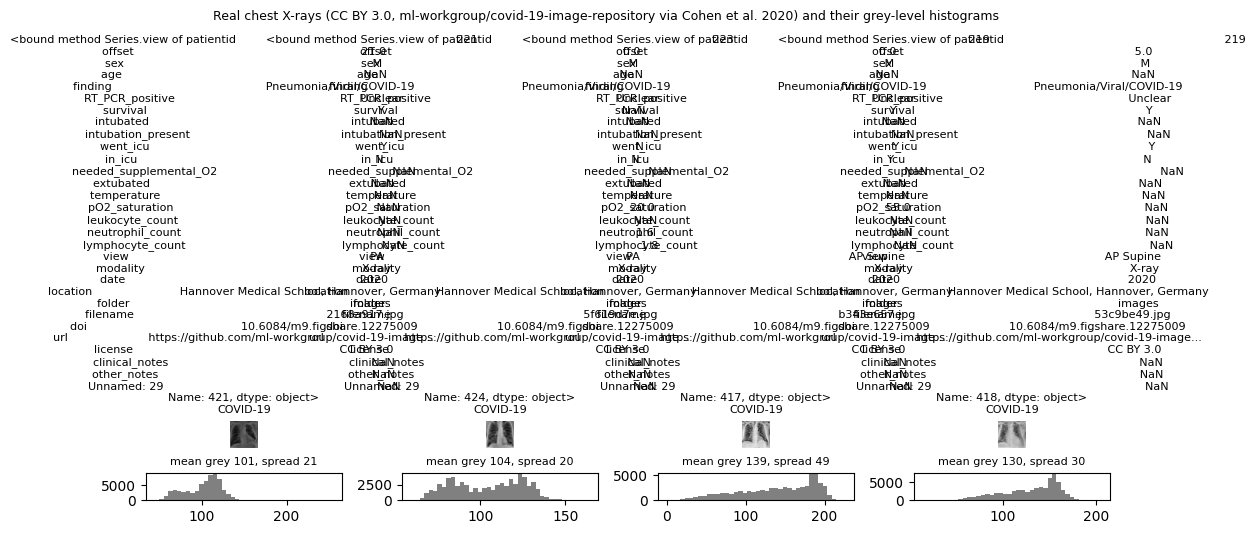

[measured] 950 metadata rows (X-ray 866, CT 84). Top label groups:
label group   rows  share
------------  ----  -----
Pneumonia     826   86.9%
todo          83    8.7% 
No Finding    22    2.3% 
Tuberculosis  18    1.9% 
Unknown       1     0.1% 
Lesson: even in this one public collection the label groups are far from balanced; several rows are labelled 'todo' or 'Unknown' (labels are not always clean).


In [24]:
if HAVE_META:
    meta = pd.read_csv(DATA_DIR / "cxr_metadata.csv")
    free = meta[(meta.license == "CC BY 3.0") & (meta.modality == "X-ray") & (meta.folder == "images")]
    pick = pd.concat([free[free.view == "PA"].head(2), free[free.view == "AP Supine"].head(2)])
    imgs, ttl = [], []
    from PIL import Image

    for _, row in pick.iterrows():
        dest = DATA_DIR / f"cxr_{row.filename}"
        if not dest.exists() and not download(CXR_RAW + "images/" + row.filename, dest, timeout=120):
            continue
        im = Image.open(dest).convert("L")
        im.thumbnail((256, 256))
        imgs.append(np.asarray(im))
        ttl.append(f"{row.view}\n{str(row.finding).split('/')[-1]}")
    if imgs:
        fig, axes = plt.subplots(2, len(imgs), figsize=(2.6 * len(imgs), 5.4))
        axes = np.atleast_2d(axes).reshape(2, -1)
        for j, (im, t) in enumerate(zip(imgs, ttl)):
            axes[0, j].imshow(im, cmap="gray")
            axes[0, j].set_title(t, fontsize=8)
            axes[0, j].axis("off")
            axes[1, j].hist(im.ravel(), bins=40, color="gray")
            axes[1, j].set_title(f"mean grey {im.mean():.0f}, spread {im.std():.0f}", fontsize=8)
        plt.suptitle("Real chest X-rays (CC BY 3.0, ml-workgroup/covid-19-image-repository via Cohen et al. 2020) and their grey-level histograms", fontsize=9)
        plt.tight_layout()
        plt.show()
    vc = meta.finding.fillna("missing").str.split("/").str[0].value_counts()
    print(f"[measured] {len(meta)} metadata rows (X-ray {int((meta.modality == 'X-ray').sum())}, CT {int((meta.modality == 'CT').sum())}). Top label groups:")
    table([[k, int(v), f"{100 * v / len(meta):.1f}%"] for k, v in vc.head(6).items()], ["label group", "rows", "share"])
    print("Lesson: even in this one public collection the label groups are far from balanced; several rows are labelled 'todo' or 'Unknown' (labels are not always clean).")
else:
    print("metadata not available offline -> skipping 7.2")

**Reading the figure.** Same body part, but different overall brightness, contrast and spread of grey levels, and different viewing geometry (PA = standing, back-to-front; AP supine = lying down). A model trained on one machine's look can fail on another's — we measure exactly that in Part 9.

### 7.3 CT and Hounsfield units: "windowing" (§6)
In CT each pixel is a **Hounsfield unit**: air ≈ −1000, lung ≈ −700 to −500, fat ≈ −100, water = 0, soft tissue ≈ +40, dense bone ≈ +700 or more (typical textbook values; `[assumed]` here — a real scan's exact values vary). A screen shows only 256 grey levels, so you pick a **window**: a centre (*level*) and *width*. Everything below the window turns black, above turns white, in between is stretched to grey. Same data, different windows, different organs visible. We build a small **synthetic phantom** with those values to show it. `[simulated]`

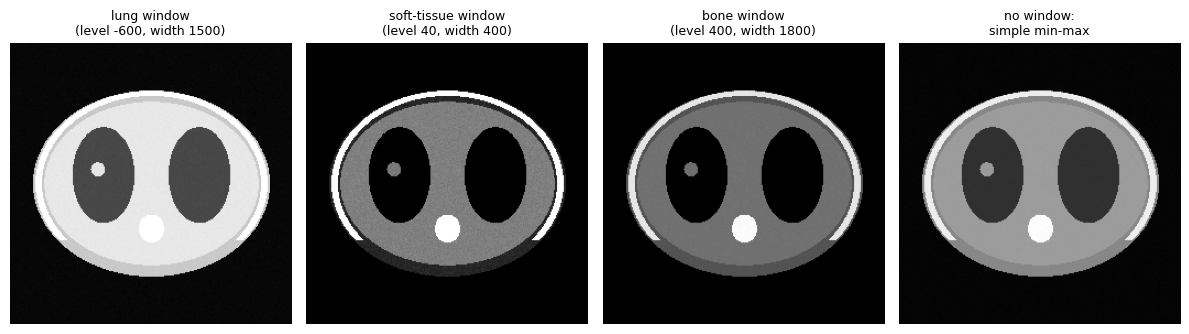

In [25]:
def make_ct_phantom(n: int = 256, seed: int = 0) -> np.ndarray:
    rng = np.random.default_rng(seed)
    yy, xx = np.mgrid[:n, :n]
    hu = np.full((n, n), -1000.0)  # air
    body = ((xx - n / 2) / (0.42 * n)) ** 2 + ((yy - n / 2) / (0.33 * n)) ** 2 < 1
    hu[body] = 40.0  # soft tissue
    hu[body & (rng.random((n, n)) < 0.0)] = 0
    fat = body & ~(((xx - n / 2) / (0.38 * n)) ** 2 + ((yy - n / 2) / (0.29 * n)) ** 2 < 1)
    hu[fat] = -100.0  # fat layer under the skin
    for cx in (0.33, 0.67):  # two lungs
        lung = ((xx - cx * n) / (0.11 * n)) ** 2 + ((yy - 0.47 * n) / (0.17 * n)) ** 2 < 1
        hu[lung] = -700.0
    spine = ((xx - n / 2) / (0.045 * n)) ** 2 + ((yy - 0.66 * n) / (0.05 * n)) ** 2 < 1
    hu[spine] = 700.0  # bone
    ribs = body & (np.abs(np.hypot(xx - n / 2, (yy - n / 2) * 1.25) - 0.40 * n) < 3) & (yy < 0.7 * n)
    hu[ribs] = 600.0
    nodule = (xx - 0.31 * n) ** 2 + (yy - 0.45 * n) ** 2 < (0.025 * n) ** 2
    hu[nodule] = 30.0  # a small soft-tissue nodule inside the left lung
    return hu + rng.normal(0, 8, hu.shape)


def apply_window(hu: np.ndarray, level: float, width: float) -> np.ndarray:
    lo, hi = level - width / 2, level + width / 2
    return np.clip((hu - lo) / (hi - lo), 0, 1)


ct = make_ct_phantom()
show_row([apply_window(ct, -600, 1500), apply_window(ct, 40, 400), apply_window(ct, 400, 1800), (ct - ct.min()) / (ct.max() - ct.min())],
         ["lung window\n(level -600, width 1500)", "soft-tissue window\n(level 40, width 400)", "bone window\n(level 400, width 1800)", "no window:\nsimple min-max"], size=3)

**Reading the figure.** The small soft-tissue nodule inside the dark lung is clearest in the lung window, where lung and nodule get many grey levels. In the soft-tissue window the whole lung is clipped to black and the nodule is dim; with plain min-max scaling everything sits in a narrow grey band because bone at +700 HU stretches the range, so contrast is lower (the nodule is still faintly visible in this noise-free toy example; a real, noisy scan would be harder). **Takeaway for model building:** always say which window (or normalisation) you used, and consider feeding two or three windows as channels. Normalising a CT like a photo can throw away the very contrast you need.

### 7.4 Why 3-D is expensive: counting the work (§7)
A 3-D CNN slides a 3×3×3 filter through a volume. We measure the arithmetic with PyTorch's `FlopCounterMode` for a 2-D slice versus a volume with 64 slices, same channels and kernel size. `[measured]`

In [26]:
from torch.utils.flop_counter import FlopCounterMode


def conv_flops(layer: nn.Module, x: torch.Tensor) -> int:
    with FlopCounterMode(display=False) as fc:
        layer(x)
    return fc.get_total_flops()


c2, c3 = nn.Conv2d(16, 32, 3, padding=1), nn.Conv3d(16, 32, 3, padding=1)
f2 = conv_flops(c2, torch.zeros(1, 16, 128, 128))
f3 = conv_flops(c3, torch.zeros(1, 16, 64, 128, 128))
p2, p3 = sum(p.numel() for p in c2.parameters()), sum(p.numel() for p in c3.parameters())
table([["2-D conv on one 128x128 slice", f"{f2 / 1e9:.2f} GFLOPs", p2], ["3-D conv on 64 slices of 128x128", f"{f3 / 1e9:.2f} GFLOPs", p3]], ["layer", "work for one image", "parameters"])
print(f"[measured] one 3-D layer on the volume costs {f3 / f2:.0f}x one 2-D slice and has {p3 / p2:.1f}x the parameters (3x3x3 vs 3x3 filters).")
print("Common compromises: process slice-by-slice (2-D), use a few neighbouring slices as channels ('2.5-D'), or crop patches from the volume.")

layer                             work for one image  parameters
--------------------------------  ------------------  ----------
2-D conv on one 128x128 slice     0.15 GFLOPs         4640      
3-D conv on 64 slices of 128x128  28.99 GFLOPs        13856     
[measured] one 3-D layer on the volume costs 192x one 2-D slice and has 3.0x the parameters (3x3x3 vs 3x3 filters).
Common compromises: process slice-by-slice (2-D), use a few neighbouring slices as channels ('2.5-D'), or crop patches from the volume.


### 7.5 Class imbalance: why 90 % accuracy can mean 0 % useful (§7)
If only 10 % of patients are sick, a model that **always says "healthy" is 90 % accurate** — and catches nobody. We reproduce that on the practice hospital: a model trained on a 10 %-sick set and tested on a 10 %-sick set, versus the same model trained after **oversampling the sick cases** (each sick scan shown 9 times, so training is 50/50). `[simulated]`

In [27]:
def train_oversampled(X: torch.Tensor, Y: torch.Tensor, factor: int, epochs: int, seed: int = SEED) -> nn.Module:
    if factor > 1:
        pos = torch.where(Y == 1)[0]
        keep = torch.cat([torch.arange(len(Y))] + [pos] * (factor - 1))
        X, Y = X[keep], Y[keep]
    return train_classifier(SmallCNN(), X, Y, epochs=epochs, seed=seed)


def sens_spec(model: nn.Module, d: dict, thr: float = 0.5) -> tuple[float, float, float]:
    p = predict_proba(model, d["X"]).numpy()
    pred, y = p >= thr, d["Y"].numpy() == 1
    sens = float((pred & y).sum() / max(y.sum(), 1))
    spec = float((~pred & ~y).sum() / max((~y).sum(), 1))
    return sens, spec, float((pred == y).mean())


D_IMB_TRAIN = build_set(_n(3000), p_tag_match=0.5, seed=11, positive_frac=0.10)
D_IMB_TEST = build_set(_n(2000), p_tag_match=0.5, seed=12, positive_frac=0.10)
print(f"[measured] sick share in imbalanced train / test: {D_IMB_TRAIN['Y'].float().mean():.3f} / {D_IMB_TEST['Y'].float().mean():.3f}  | 'always healthy' accuracy on test = {1 - D_IMB_TEST['Y'].float().mean():.3f}")
rows = []
for nm, f_ in [("plain training on the 10 %-sick data", 1), ("sick scans oversampled x9 (training 50/50)", 9)]:
    mdl = train_oversampled(D_IMB_TRAIN["X"], D_IMB_TRAIN["Y"], f_, epochs=8 if not QUICK else 2)
    se, sp, ac = sens_spec(mdl, D_IMB_TEST)
    rows.append([nm, f"{ac:.3f}", f"{se:.3f}", f"{sp:.3f}"])
table(rows, ["training", "accuracy", "sensitivity (sick caught)", "specificity (healthy cleared)"])

[measured] sick share in imbalanced train / test: 0.101 / 0.100  | 'always healthy' accuracy on test = 0.900
training                                    accuracy  sensitivity (sick caught)  specificity (healthy cleared)
------------------------------------------  --------  -------------------------  -----------------------------
plain training on the 10 %-sick data        0.900     0.000                      1.000                        
sick scans oversampled x9 (training 50/50)  1.000     1.000                      1.000                        


**Reading the result.** Look at accuracy *and* sensitivity side by side. If the plain model's accuracy is close to the "always healthy" figure and its sensitivity is near 0, accuracy was hiding the failure. Oversampling (or class weights) changes what the model is pushed to learn; whether a given trade-off between sensitivity and specificity is acceptable is a **clinical** decision (Part 9), not a coding one. In PP13 you must **check the imbalance in your actual split** before choosing a fix (§13 of the brief). (Class weights were also tried while preparing this notebook, with the same small CNN, and did not get this small network to learn from so few sick cases in 8 epochs — a reminder that "the standard fix" must be tested, not assumed.)

### 7.6 The domain gap (why ImageNet weights can still help — and what can go wrong)
**Domain gap** = the training pictures (ImageNet: cats, cars) look statistically different from your target pictures (greyscale chest X-rays). Early layers learn generic edges and textures that transfer well; late layers learn object-specific parts that may not. We measure the practical effect in Part 8 by comparing a pretrained and a from-scratch ResNet on the same data. Caution (§7): pretrained **does not** mean "better" automatically — you must test it.

### 7.7 Data scarcity, privacy and dataset bias (§7) — no code, but the reasons behind many decisions
* **Scarce labels.** A label (e.g. "outline this tumour") costs an expert minutes to hours, and experts disagree. So medical sets are small, and *augmentation*, *transfer learning* and *self-supervised pre-training* matter.
* **Privacy.** Scans and metadata are personal health data. Rules (e.g. HIPAA in the US, GDPR in the EU) limit sharing; data is de-identified, access is controlled, and a *model* can also leak information about its training patients. Practical habit: never commit patient data or identifying metadata to a repository, and keep a note of the dataset's licence, as we did for the X-ray images above.
* **Dataset bias.** Data comes from particular hospitals, machines, ages and regions. A model learns whatever separates the labels *in that data* — including scanner marks, text overlays, or hospital identity (Part 1 reproduced this on purpose). Always ask: **what else differs between the sick and healthy images besides the disease?**

# Part 8 — Medical models: transfer learning, U-Net segmentation, Dice and IoU (§7–§8)
### 🧒 In simple words
* **Classification** answers *"is this patient sick?"* — one answer per image (PP13 Task A).
* **Segmentation** answers *"which pixels are the lesion?"* — one answer per pixel (PP13 Task B). It is a **map**, so a doctor can see *where* and *how big*.

**Transfer learning** = start from a network that already learned generic edges and textures on millions of photos (ImageNet) and *fine-tune* it on your small medical set. Usually helps when data is scarce — but you must **check** (domain gap, Part 7.6).

**U-Net** = an encoder squeezes the image to find *what* is there, a decoder expands it back to find *where*, and **skip connections** carry sharp detail straight from encoder to decoder — "the decoder gets a cheat-sheet of the fine details". Without skips, outlines get blurry.

**Dice** and **IoU** measure how well two masks overlap: *overlap ÷ (size of both)* — 1 = perfect, 0 = no overlap.
* IoU = |A∩B| ÷ |A∪B|     * Dice = 2|A∩B| ÷ (|A|+|B|)    * They are linked: **Dice = 2·IoU ÷ (1+IoU)**, so they rank models the same way, but Dice always looks a bit higher.
* **Pixel accuracy is a trap**: a lesion covers a tiny fraction of pixels, so "predict nothing" scores about 96 % pixel accuracy on sick scans (measured below) and 0 Dice.

### 8.1 Transfer learning on a small training set (ResNet-18)
Does ImageNet pre-training help when we only have **400** labelled scans? Three versions of the same ResNet-18 (grey image copied to 3 channels, images 64×64), trained identically for a few epochs, evaluated on the clean test set; mean ± spread over seeds. `[measured]`
1. **scratch** — random start.
2. **fine-tune all** — pretrained start, all layers updated.
3. **fine-tune last stage only** — pretrained, early layers frozen (only `layer4` and the new head train).

In [28]:
def make_resnet(pretrained: bool, freeze_early: bool = False) -> nn.Module:
    from torchvision.models import resnet18

    net = load_resnet18_pretrained() if pretrained else resnet18()
    net.fc = nn.Linear(512, 2)
    if freeze_early:
        for n_, p in net.named_parameters():
            p.requires_grad = n_.startswith(("layer4", "fc"))
    return net


def to_rgb_norm(X: torch.Tensor) -> torch.Tensor:
    return (X.repeat(1, 3, 1, 1) - IMN_MEAN) / IMN_STD


def train_resnet(net: nn.Module, X: torch.Tensor, Y: torch.Tensor, epochs: int, lr: float = 1e-3, seed: int = 0) -> nn.Module:
    torch.manual_seed(seed)
    opt = torch.optim.AdamW([p for p in net.parameters() if p.requires_grad], lr, weight_decay=1e-4)
    Xn = to_rgb_norm(X)
    for _ in range(epochs):
        net.train()
        perm = torch.randperm(len(Xn))
        for i in range(0, len(Xn), 32):
            idx = perm[i:i + 32]
            loss = F.cross_entropy(net(Xn[idx]), Y[idx])
            opt.zero_grad()
            loss.backward()
            opt.step()
    return net.eval()


class RGBWrap(nn.Module):
    """Lets the explanation code feed a plain 1-channel image to a 3-channel ResNet."""

    def __init__(self, net: nn.Module) -> None:
        super().__init__()
        self.net = net

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.net(to_rgb_norm(x))


def auc_of(model: nn.Module, d: dict) -> tuple[float, float]:
    p = predict_proba(model, d["X"]).numpy()
    return float(((p > 0.5) == d["Y"].numpy()).mean()), float(roc_auc_score(d["Y"].numpy(), p))


if HAVE_R18:
    n_small = 120 if QUICK else 400
    seeds = [0] if QUICK else [0, 1, 2]
    Xs, Ys = D_TRAIN_CLEAN["X"][:n_small], D_TRAIN_CLEAN["Y"][:n_small]
    results: dict[str, list[tuple[float, float]]] = {}
    FIRST_NETS: dict[str, nn.Module] = {}
    t0 = time.time()
    for name, pre, frz in [("scratch", False, False), ("fine-tune all", True, False), ("fine-tune last stage only", True, True)]:
        for sd in seeds:
            net = train_resnet(make_resnet(pre, frz), Xs, Ys, epochs=2 if QUICK else 6, seed=sd)
            wrapped = RGBWrap(net).eval()
            results.setdefault(name, []).append((*auc_of(wrapped, D_TEST_CLEAN), auc_of(wrapped, D_MID_TEST)[0]))
            if sd == seeds[0]:
                FIRST_NETS[name] = wrapped
    table([[k, f"{np.mean([a for a, _, _ in v]):.3f} ± {np.std([a for a, _, _ in v]):.3f}", f"{np.mean([u for _, u, _ in v]):.3f} ± {np.std([u for _, u, _ in v]):.3f}", f"{np.mean([f for _, _, f in v]):.3f} ± {np.std([f for _, _, f in v]):.3f}"] for k, v in results.items()],
          [f"ResNet-18 on {n_small} training scans ({len(seeds)} seeds)", "accuracy, normal test", "AUC, normal test", "accuracy, fainter-lesion test (harder)"])
    print(f"({time.time() - t0:.0f}s) Spread = standard deviation over seeds; with few seeds it is only a rough guide.")
else:
    print("pretrained ResNet-18 not available offline -> skipping 8.1")

ResNet-18 on 400 training scans (3 seeds)  accuracy, normal test  AUC, normal test  accuracy, fainter-lesion test (harder)
-----------------------------------------  ---------------------  ----------------  --------------------------------------
scratch                                    0.997 ± 0.003          1.000 ± 0.000     0.881 ± 0.077                         
fine-tune all                              1.000 ± 0.000          1.000 ± 0.000     0.856 ± 0.044                         
fine-tune last stage only                  0.976 ± 0.005          0.998 ± 0.000     0.709 ± 0.018                         
(287s) Spread = standard deviation over seeds; with few seeds it is only a rough guide.


**Reading the result.** On the normal test set scratch and fine-tune-all are both perfect, so pre-training shows no benefit there; on the harder fainter-lesion test the scratch and fine-tune-all means differ by less than the seed spread (so no winner can be claimed), and freezing the early layers is clearly worse. Compare the three rows *including the spread*. If a difference is smaller than the spread, do not claim one is better. Also remember the task is synthetic and easy: the point here is the **method** (how to set up and honestly compare transfer vs scratch), not the exact numbers. In PP13 the same comparison on real data is the evidence you need before saying "pretraining helped".

### 8.2 Where does the fine-tuned ResNet look? (Grad-CAM on a medical-style task)
Same `grad_cam` function as Part 3, now on the ResNet's last stage `layer4`. At 64×64 input that layer is only 2×2, so the heat is very blocky — a concrete example of the resolution/relevance trade-off. We also test the earlier stage `layer3` (4×4). `[measured]`

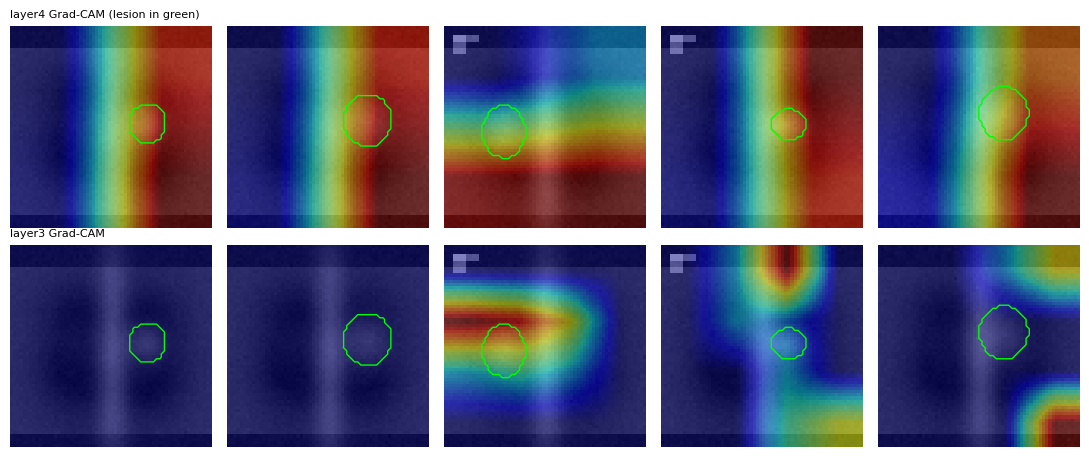

fine-tuned ResNet-18, 40 correctly-detected sick scans  heat energy on lesion  peak on lesion
------------------------------------------------------  ---------------------  --------------
layer4 (2x2)                                            0.10                   0.03          
layer3 (4x4)                                            0.10                   0.12          


In [29]:
if HAVE_R18:
    net_ft = FIRST_NETS["fine-tune all"]
    rows = []
    fig, axes = plt.subplots(2, 5, figsize=(11, 4.6))
    cases = [int(i) for i in torch.where(D_TEST_CLEAN["Y"] == 1)[0][:60] if float(predict_proba(net_ft, D_TEST_CLEAN["X"][int(i):int(i) + 1])) > 0.5][: (10 if QUICK else 40)]
    for lname, lay in [("layer4 (2x2)", net_ft.net.layer4), ("layer3 (4x4)", net_ft.net.layer3)]:
        ens, hits = [], []
        for i in cases:
            h, e = region_stats(grad_cam(net_ft, lay, D_TEST_CLEAN["X"][i:i + 1], 1), D_TEST_CLEAN["M"][i, 0].numpy())
            hits.append(h), ens.append(e)
        rows.append([lname, f"{np.mean(ens):.2f}", f"{np.mean(hits):.2f}"])
    for j, i in enumerate(cases[:5]):
        x = D_TEST_CLEAN["X"][i:i + 1]
        for r, lay in enumerate([net_ft.net.layer4, net_ft.net.layer3]):
            axes[r, j].imshow(x[0, 0], vmin=0, vmax=1)
            axes[r, j].imshow(grad_cam(net_ft, lay, x, 1), cmap="jet", alpha=0.5)
            axes[r, j].contour(D_TEST_CLEAN["M"][i, 0], levels=[0.5], colors="lime", linewidths=1)
            axes[r, j].axis("off")
    axes[0, 0].set_title("layer4 Grad-CAM (lesion in green)", fontsize=8, loc="left")
    axes[1, 0].set_title("layer3 Grad-CAM", fontsize=8, loc="left")
    plt.tight_layout()
    plt.show()
    table(rows, [f"fine-tuned ResNet-18, {len(cases)} correctly-detected sick scans", "heat energy on lesion", "peak on lesion"])

### 8.3 A small U-Net — with and without skip connections
Two identical U-Nets (3 levels) except that one has the skip connections **cut** (the decoder gets zeros instead of the encoder's detail). Trained to output a lesion probability for each pixel with *BCE + Dice* loss (BCE alone would be tempted to predict "no lesion" everywhere, because lesion pixels are rare). Evaluated on the **sick** test scans. `[measured]`

In [30]:
def conv_block(i: int, o: int) -> nn.Sequential:
    return nn.Sequential(nn.Conv2d(i, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(), nn.Conv2d(o, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU())


class UNet(nn.Module):
    def __init__(self, skips: bool = True, c: int = 16) -> None:
        super().__init__()
        self.skips = skips
        self.enc1, self.enc2, self.enc3 = conv_block(1, c), conv_block(c, 2 * c), conv_block(2 * c, 4 * c)  # enc3 = bottleneck
        self.up2, self.up1 = nn.ConvTranspose2d(4 * c, 2 * c, 2, 2), nn.ConvTranspose2d(2 * c, c, 2, 2)
        self.dec2, self.dec1 = conv_block(4 * c, 2 * c), conv_block(2 * c, c)
        self.out = nn.Conv2d(c, 1, 1)

    def forward(self, x: torch.Tensor) -> torch.Tensor:  # returns LOGITS (B,1,H,W)
        e1 = self.enc1(x)
        e2 = self.enc2(F.max_pool2d(e1, 2))
        e3 = self.enc3(F.max_pool2d(e2, 2))
        s2, s1 = (e2, e1) if self.skips else (torch.zeros_like(e2), torch.zeros_like(e1))
        d2 = self.dec2(torch.cat([self.up2(e3), s2], 1))
        d1 = self.dec1(torch.cat([self.up1(d2), s1], 1))
        return self.out(d1)


def dice_iou(prob: torch.Tensor, mask: torch.Tensor, thr: float = 0.5, eps: float = 1e-6) -> tuple[float, float]:
    """Mean Dice and IoU over a batch of (B,1,H,W) probabilities vs binary masks (per-image, then averaged)."""
    p = (prob >= thr).float().flatten(1)
    g = mask.flatten(1)
    inter = (p * g).sum(1)
    dice = (2 * inter + eps) / (p.sum(1) + g.sum(1) + eps)
    iou = (inter + eps) / (p.sum(1) + g.sum(1) - inter + eps)
    return float(dice.mean()), float(iou.mean())


def train_unet(skips: bool, X: torch.Tensor, M: torch.Tensor, epochs: int, seed: int = SEED) -> UNet:
    torch.manual_seed(seed)
    net = UNet(skips)
    opt = torch.optim.Adam(net.parameters(), 2e-3)
    for _ in range(epochs):
        net.train()
        perm = torch.randperm(len(X))
        for i in range(0, len(X), 32):
            idx = perm[i:i + 32]
            logit = net(X[idx])
            p = torch.sigmoid(logit)
            inter = (p * M[idx]).sum((1, 2, 3))
            dice_l = 1 - ((2 * inter + 1) / (p.sum((1, 2, 3)) + M[idx].sum((1, 2, 3)) + 1)).mean()
            loss = F.binary_cross_entropy_with_logits(logit, M[idx]) + dice_l
            opt.zero_grad()
            loss.backward()
            opt.step()
    return net.eval()


@torch.no_grad()
def unet_prob(net: UNet, X: torch.Tensor) -> torch.Tensor:
    return torch.cat([torch.sigmoid(net(X[i:i + 128])) for i in range(0, len(X), 128)])


t0 = time.time()
sick_te = torch.where(D_TEST_CLEAN["Y"] == 1)[0]
UNETS = {k: train_unet(k, D_TRAIN_CLEAN["X"], D_TRAIN_CLEAN["M"], epochs=3 if QUICK else 12) for k in (True, False)}
rows = []
for k, net in UNETS.items():
    pr = unet_prob(net, D_TEST_CLEAN["X"][sick_te])
    d, j = dice_iou(pr, D_TEST_CLEAN["M"][sick_te])
    pix = float(((pr >= 0.5).float() == D_TEST_CLEAN["M"][sick_te]).float().mean())
    sick_f = torch.where(D_MID_TEST["Y"] == 1)[0]
    df_, _ = dice_iou(unet_prob(net, D_MID_TEST["X"][sick_f]), D_MID_TEST["M"][sick_f])
    rows.append(["U-Net with skips" if k else "U-Net WITHOUT skips", f"{d:.3f}", f"{j:.3f}", f"{pix:.3f}", f"{2 * j / (1 + j):.3f}", f"{df_:.3f}"])
bg = 1 - float(D_TEST_CLEAN["M"][sick_te].mean())
table(rows, ["model", "Dice", "IoU", "pixel accuracy", "2*IoU/(1+IoU)", "Dice on fainter lesions"])
print(f"({time.time() - t0:.0f}s) [measured] 'predict no lesion anywhere' would get pixel accuracy {bg:.3f} and Dice 0.000 — pixel accuracy hides the failure.")
print("Note: the last column is computed from the mean IoU; because Dice and IoU are averaged per image the identity holds per image and only approximately for the means.")

model                Dice   IoU    pixel accuracy  2*IoU/(1+IoU)  Dice on fainter lesions
-------------------  -----  -----  --------------  -------------  -----------------------
U-Net with skips     0.973  0.947  0.998           0.973          0.330                  
U-Net WITHOUT skips  0.977  0.956  0.998           0.977          0.553                  
(425s) [measured] 'predict no lesion anywhere' would get pixel accuracy 0.963 and Dice 0.000 — pixel accuracy hides the failure.
Note: the last column is computed from the mean IoU; because Dice and IoU are averaged per image the identity holds per image and only approximately for the means.


**Reading the result.** (1) The pixel-accuracy column is almost identical for every model — it is dominated by the empty background, so it cannot tell a good segmenter from a useless one; Dice/IoU can. (2) Compare the "with skips" and "without skips" rows. In this run the gap on the normal test is small (about 0.01 Dice) and on the fainter-lesion test the order is *reversed*; with one training seed per variant we therefore **cannot claim** that skip connections helped on this easy synthetic task (they are expected to matter more for fine boundaries in real images — a claim to test, not assume). (3) Dice is always ≥ IoU. In PP13 report **both** and say whether numbers are per-image means or computed over the whole test set.

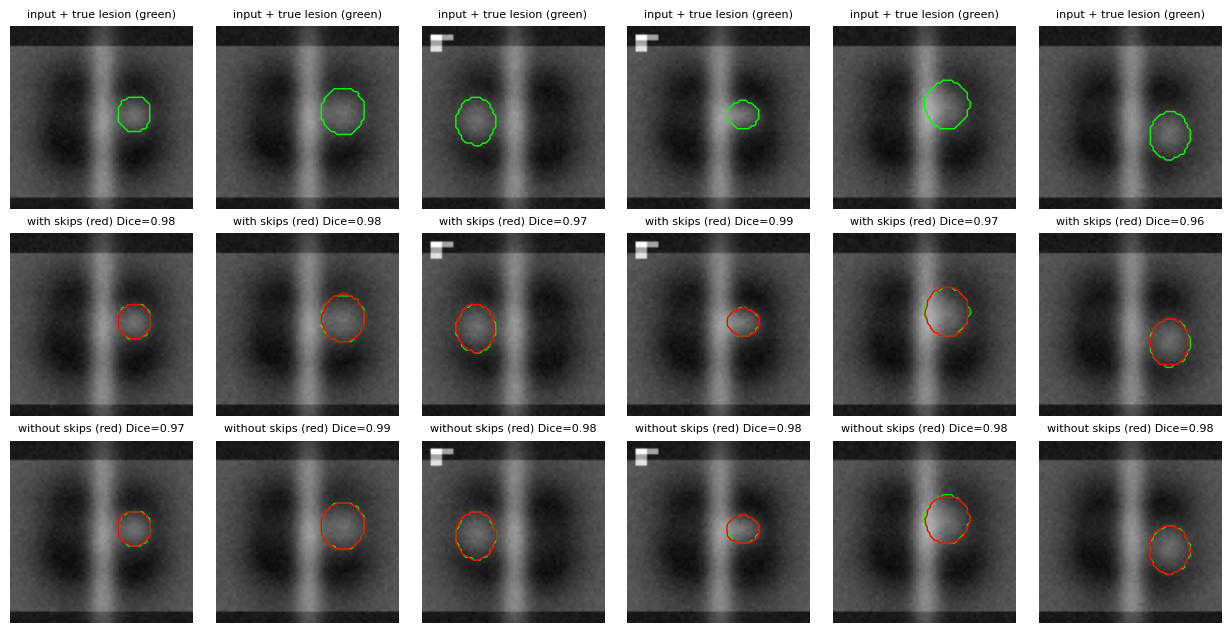

In [31]:
fig, axes = plt.subplots(3, 6, figsize=(12.5, 6.4))
for j, i in enumerate(sick_te[:6].tolist()):
    x = D_TEST_CLEAN["X"][i:i + 1]
    axes[0, j].imshow(x[0, 0], vmin=0, vmax=1)
    axes[0, j].contour(D_TEST_CLEAN["M"][i, 0], levels=[0.5], colors="lime", linewidths=1)
    axes[0, j].set_title("input + true lesion (green)", fontsize=8)
    for r, k in enumerate([True, False], start=1):
        pr = unet_prob(UNETS[k], x)
        axes[r, j].imshow(x[0, 0], vmin=0, vmax=1)
        axes[r, j].contour(D_TEST_CLEAN["M"][i, 0], levels=[0.5], colors="lime", linewidths=0.8)
        axes[r, j].contour(pr[0, 0], levels=[0.5], colors="red", linewidths=1)
        axes[r, j].set_title(f"{'with' if k else 'without'} skips (red) Dice={dice_iou(pr, D_TEST_CLEAN['M'][i:i + 1])[0]:.2f}", fontsize=8)
for a in axes.ravel():
    a.axis("off")
plt.tight_layout()
plt.show()

### 8.4 Explaining a *segmentation* model — adapting, not copying (PP13 asks for this)
A classifier has one score; a segmenter has *thousands* (one per pixel). So the question "why this output?" must be **re-asked**: *"why did the model mark **this region** as lesion?"* Two adaptations (this follows **Seg-Grad-CAM**, Vinogradova, Dibrov & Myers, AAAI 2020 student abstract, arXiv:2002.11434, which replaces the class score by the sum of the logits over a set of output pixels of interest; the code below is our own simple implementation):
* **Seg-Grad-CAM**: the score to explain is the **sum of the lesion logits inside the predicted region** (instead of the class logit). The rest of Grad-CAM is unchanged.
* **Region occlusion**: hide a patch and measure how much the **total predicted lesion probability inside the original lesion region** falls.

Then we ask the same question as before: does the heat land on the lesion? Layer matters: the **bottleneck** (`enc3`, 16×16) or a decoder layer (`dec1`, 64×64). `[measured]`

explaining the U-Net's lesion output (30 well-segmented scans)  heat energy on true lesion  peak on lesion
--------------------------------------------------------------  --------------------------  --------------
Seg-Grad-CAM @ bottleneck enc3 (16x16)                          0.21                        1.00          
Seg-Grad-CAM @ decoder dec1 (64x64)                             1.00                        1.00          
region occlusion                                                0.72                        1.00          


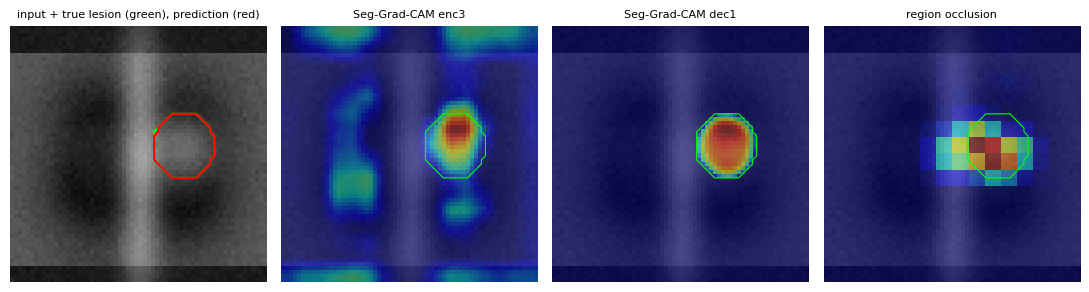

In [32]:
def seg_grad_cam(net: UNet, layer: nn.Module, x: torch.Tensor, region: torch.Tensor) -> torch.Tensor:
    """Grad-CAM where the explained score is sum(logit * region) — 'why is THIS region lesion?'. region: (1,1,H,W) 0/1."""
    store: dict[str, torch.Tensor] = {}

    def hook(_m, _i, out):
        store["a"] = out
        out.register_hook(lambda g: store.__setitem__("g", g))

    h = layer.register_forward_hook(hook)
    try:
        net.zero_grad()
        (net(x) * region).sum().backward()
    finally:
        h.remove()
    a, g = store["a"].detach(), store["g"]
    cam = F.relu((g.mean((2, 3), keepdim=True) * a).sum(1, keepdim=True))
    cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)[:, 0]
    return _normalise(cam)[0]


@torch.no_grad()
def seg_occlusion(net: UNet, x: torch.Tensor, region: torch.Tensor, patch: int = 8, stride: int = 4) -> torch.Tensor:
    base = float((torch.sigmoid(net(x)) * region).sum())
    fill = float(x.mean())
    H, W = x.shape[-2:]
    heat, cnt = torch.zeros(H, W), torch.zeros(H, W)
    for r in range(0, H - patch + 1, stride):
        for c in range(0, W - patch + 1, stride):
            xo = x.clone()
            xo[..., r:r + patch, c:c + patch] = fill
            drop = base - float((torch.sigmoid(net(xo)) * region).sum())
            heat[r:r + patch, c:c + patch] += drop
            cnt[r:r + patch, c:c + patch] += 1
    return (heat / cnt.clamp_min(1)).clamp_min(0)


net_seg = UNETS[True]
_cand = sorted(((dice_iou(unet_prob(net_seg, D_TEST_CLEAN["X"][i:i + 1]), D_TEST_CLEAN["M"][i:i + 1])[0], i) for i in sick_te.tolist()[:80]), reverse=True)
good = [i for d_, i in _cand if d_ > 0.5][: (8 if QUICK else 30)]
if len(good) < 3:  # only happens with a badly under-trained model (e.g. QUICK smoke test)
    print("warning: fewer than 3 scans with Dice > 0.5 -> using the 5 best-segmented scans instead")
    good = [i for _, i in _cand[:5]]
rows = []
for nm, fn in [("Seg-Grad-CAM @ bottleneck enc3 (16x16)", lambda x, r: seg_grad_cam(net_seg, net_seg.enc3, x, r)),
               ("Seg-Grad-CAM @ decoder dec1 (64x64)", lambda x, r: seg_grad_cam(net_seg, net_seg.dec1, x, r)),
               ("region occlusion", lambda x, r: _norm01(seg_occlusion(net_seg, x, r)))]:
    ens, hits = [], []
    for i in good:
        x = D_TEST_CLEAN["X"][i:i + 1]
        pred_region = (unet_prob(net_seg, x) >= 0.5).float()
        h, e = region_stats(fn(x, pred_region), D_TEST_CLEAN["M"][i, 0].numpy())
        hits.append(h), ens.append(e)
    rows.append([nm, f"{np.mean(ens):.2f}", f"{np.mean(hits):.2f}"])
table(rows, [f"explaining the U-Net's lesion output ({len(good)} well-segmented scans)", "heat energy on true lesion", "peak on lesion"])
fig, axes = plt.subplots(1, 4, figsize=(11, 3.2))
i = good[0]
x = D_TEST_CLEAN["X"][i:i + 1]
pr_reg = (unet_prob(net_seg, x) >= 0.5).float()
for ax, (img, ttl) in zip(axes, [(None, "input + true lesion (green), prediction (red)"), (seg_grad_cam(net_seg, net_seg.enc3, x, pr_reg), "Seg-Grad-CAM enc3"), (seg_grad_cam(net_seg, net_seg.dec1, x, pr_reg), "Seg-Grad-CAM dec1"), (_norm01(seg_occlusion(net_seg, x, pr_reg)), "region occlusion")]):
    ax.imshow(x[0, 0], vmin=0, vmax=1)
    if img is None:
        ax.contour(D_TEST_CLEAN["M"][i, 0], levels=[0.5], colors="lime")
        ax.contour(pr_reg[0, 0], levels=[0.5], colors="red")
    else:
        ax.imshow(img, cmap="jet", alpha=0.5)
        ax.contour(D_TEST_CLEAN["M"][i, 0], levels=[0.5], colors="lime", linewidths=0.8)
    ax.set_title(ttl, fontsize=8)
    ax.axis("off")
plt.tight_layout()
plt.show()

**Reading the result.** The decoder-layer row (`dec1`, 64×64) scores 1.00 almost by construction — that layer *is* the output being explained — so only the bottleneck and occlusion rows carry information: the bottleneck heat is coarse (peak on the lesion in most scans, but only ~20 % of its energy inside it), occlusion is more concentrated. For a segmentation model the *lesion itself* is almost always inside the highlighted region (the model is, after all, looking at what it outlines), so a high "share on lesion" is **less informative** than in classification. The more useful questions are: does the heat extend to **context outside** the lesion that the model relies on (e.g. the corner marker, if it had been trained on biased data)? Which layer gives a usable resolution? This is the Task-B adaptation PP13 asks you to justify rather than copy from Task A.

# Part 9 — Clinical evaluation: sensitivity, specificity, thresholds, and hospital shift (§9, §10)
### 🧒 In simple words
Doctors do not ask "what % did it get right?" They ask two questions:
* **Sensitivity** (recall, true-positive rate): *Of the patients who ARE sick, how many did the model catch?* → misses are **false negatives**.
* **Specificity** (true-negative rate): *Of the patients who are healthy, how many did the model correctly clear?* → mistakes are **false positives** (false alarms).

The model outputs a probability; a **threshold** turns it into "sick / healthy". Lower threshold → catches more sick patients (sensitivity ↑) but raises more false alarms (specificity ↓). **The threshold is a clinical choice** about which mistake is worse — PP13 asks you to *state* it, not just use 0.5.

And one more trap: **PPV** (positive predictive value) — *"if the model says sick, how likely is it that the patient really is?"* — depends on how common the disease is. Rare disease ⇒ most alarms are false even for a good test.

### 9.1 The confusion matrix and the two numbers
On a test set of **early-stage scans** (the same hospital, but *faint* lesions — about a quarter of the contrast of the training lesions), Model C, default threshold 0.5. We use faint lesions on purpose: on strong lesions the model is perfect and every metric is 1.0, which teaches nothing. `[measured]`

In [33]:
def confusion(model: nn.Module, d: dict, thr: float = 0.5) -> dict[str, int]:
    p = predict_proba(model, d["X"]).numpy()
    pred, y = p >= thr, d["Y"].numpy() == 1
    return dict(TP=int((pred & y).sum()), FN=int((~pred & y).sum()), FP=int((pred & ~y).sum()), TN=int((~pred & ~y).sum()))


cm = confusion(MODEL_C, D_FAINT_TEST)
table([["truly sick", cm["TP"], cm["FN"]], ["truly healthy", cm["FP"], cm["TN"]]], ["", "model says SICK", "model says HEALTHY"])
sens, spec = cm["TP"] / (cm["TP"] + cm["FN"]), cm["TN"] / (cm["TN"] + cm["FP"])
ppv = cm["TP"] / max(cm["TP"] + cm["FP"], 1)
print(f"[measured] sensitivity = TP/(TP+FN) = {sens:.3f} | specificity = TN/(TN+FP) = {spec:.3f} | PPV on this 50%-sick test set = {ppv:.3f}")

               model says SICK  model says HEALTHY
-------------  ---------------  ------------------
truly sick     288              212               
truly healthy  0                500               
[measured] sensitivity = TP/(TP+FN) = 0.576 | specificity = TN/(TN+FP) = 1.000 | PPV on this 50%-sick test set = 1.000


### 9.2 Choosing the threshold
We sweep the threshold, draw the **ROC curve** (sensitivity vs 1 − specificity), and then pick a threshold the way a clinical team would: **fix a target first** (here: *catch at least 95 % of sick patients*), choose the threshold on a **separate validation set** (never on the test set!), and *then* report what that costs in specificity on the test set. We also show a cost view: if a missed patient is assumed 10× worse than a false alarm (`[assumed]` — a number the clinical team must supply), which threshold minimises expected cost? `[measured]` given those assumptions.

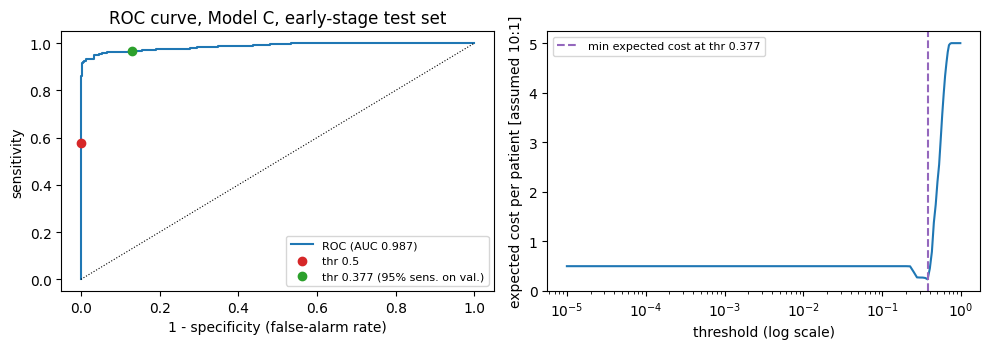

threshold rule                                        test sensitivity  test specificity  test accuracy
----------------------------------------------------  ----------------  ----------------  -------------
default 0.5                                           0.576             1.000             0.788        
95%-sensitivity target (chosen on validation: 0.377)  0.966             0.870             0.918        
min cost, FN:FP = 10:1 (thr 0.377)                    0.966             0.870             0.918        


In [34]:
p_val = predict_proba(MODEL_C, D_FAINT_VAL["X"]).numpy()
y_val = D_FAINT_VAL["Y"].numpy() == 1
thr_grid = np.unique(np.concatenate([np.logspace(-5, -1.5, 30), np.linspace(0.05, 0.98, 38)]))  # fine grid, including very low thresholds
# highest threshold that still reaches >=95% sensitivity on validation
ok = [t for t in thr_grid if (p_val[y_val] >= t).mean() >= 0.95]
thr_95 = max(ok) if ok else float(thr_grid.min())
fpr, tpr, _ = roc_curve(D_FAINT_TEST["Y"].numpy(), predict_proba(MODEL_C, D_FAINT_TEST["X"]).numpy())
auc = roc_auc_score(D_FAINT_TEST["Y"].numpy(), predict_proba(MODEL_C, D_FAINT_TEST["X"]).numpy())
c_fn, c_fp = 10.0, 1.0  # [assumed] relative costs
p_te = predict_proba(MODEL_C, D_FAINT_TEST["X"]).numpy()
y_te = D_FAINT_TEST["Y"].numpy() == 1
cost = [(c_fn * ((p_te < t) & y_te).sum() + c_fp * ((p_te >= t) & ~y_te).sum()) / len(y_te) for t in thr_grid]
thr_cost = float(thr_grid[int(np.argmin(cost))])
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].plot(fpr, tpr, label=f"ROC (AUC {auc:.3f})")
for t, c, nm in [(0.5, "tab:red", "thr 0.5"), (thr_95, "tab:green", f"thr {thr_95:.3g} (95% sens. on val.)")]:
    s_, sp_, _ = sens_spec(MODEL_C, D_FAINT_TEST, t)
    ax[0].scatter([1 - sp_], [s_], color=c, zorder=3, label=nm)
ax[0].plot([0, 1], [0, 1], "k:", lw=0.8)
ax[0].set_xlabel("1 - specificity (false-alarm rate)")
ax[0].set_ylabel("sensitivity")
ax[0].legend(fontsize=8)
ax[0].set_title("ROC curve, Model C, early-stage test set")
ax[1].plot(thr_grid, cost)
ax[1].axvline(thr_cost, color="tab:purple", ls="--", label=f"min expected cost at thr {thr_cost:.3g}")
ax[1].set_xscale("log")
ax[1].set_xlabel("threshold (log scale)")
ax[1].set_ylabel("expected cost per patient [assumed 10:1]")
ax[1].legend(fontsize=8)
plt.tight_layout()
plt.show()
rows = []
for nm, t in [("default 0.5", 0.5), (f"95%-sensitivity target (chosen on validation: {thr_95:.3g})", thr_95), (f"min cost, FN:FP = 10:1 (thr {thr_cost:.3g})", thr_cost)]:
    s_, sp_, a_ = sens_spec(MODEL_C, D_FAINT_TEST, t)
    rows.append([nm, f"{s_:.3f}", f"{sp_:.3f}", f"{a_:.3f}"])
table(rows, ["threshold rule", "test sensitivity", "test specificity", "test accuracy"])

**Reading the result.** Notice the pattern: the model still *ranks* faint-lesion patients well (look at the AUC) but at the default 0.5 threshold it misses many of them, because its scores for faint lesions are lower than for the strong lesions it was trained on. Moving the threshold buys sensitivity back at a cost in specificity. One model, one ROC curve, many possible operating points. Which row is "best" depends entirely on the clinical context. In PP13 write: *the threshold, how you chose it (on which data), and the sensitivity/specificity it gives on the test set.* Note the validation set was used to choose the threshold; the test set only to report — mixing them up inflates the result.

### 9.3 Prevalence and PPV: why rare diseases make alarms unreliable
Pure arithmetic (Bayes' rule), `[computed]` from the sensitivity and specificity measured above at two operating points: how often is a positive prediction correct when the share of sick patients in the population is 50 %, 10 % or 1 %?

In [35]:
s95, sp95, _ = sens_spec(MODEL_C, D_FAINT_TEST, thr_95)
ops = [("threshold 0.5", sens, spec), (f"95%-sensitivity threshold ({thr_95:.3g})", s95, sp95)]


def ppv_at(se: float, sp: float, prev: float) -> float:
    return (se * prev) / max(se * prev + (1 - sp) * (1 - prev), 1e-12)


table([[f"{prev:.0%}"] + [f"{ppv_at(se, sp, prev):.3f}" for _, se, sp in ops] for prev in (0.5, 0.1, 0.01)], ["disease prevalence"] + [f"PPV @ {nm} (sens {se:.2f}, spec {sp:.2f})" for nm, se, sp in ops])

disease prevalence  PPV @ threshold 0.5 (sens 0.58, spec 1.00)  PPV @ 95%-sensitivity threshold (0.377) (sens 0.97, spec 0.87)
------------------  ------------------------------------------  --------------------------------------------------------------
50%                 1.000                                       0.881                                                         
10%                 1.000                                       0.452                                                         
1%                  1.000                                       0.070                                                         


**Reading the result.** At the default threshold the model's specificity is (almost) perfect, so its alarms stay trustworthy even for rare disease — but it misses many faint cases. At the threshold chosen for high sensitivity, specificity drops, and the PPV falls quickly as the disease gets rarer: most alarms become false. That is the price of "catch almost everyone" in a screening setting, and exactly why sensitivity, specificity **and** prevalence must be discussed together.

### 9.4 Hospital shift: the same model at a different hospital (§9)
Hospital 1 uses another scanner: more contrast, a brightness offset and more noise (the `SITE_STYLE` setting in Part 0). The disease is exactly the same. We test Model C (trained only on Hospital 0) at Hospital 1, then try two realistic remedies: (a) **train with a bit of data from both hospitals**; (b) **re-choose the threshold** for the new hospital on a small local validation set. `[simulated]`

setting                                                sensitivity  specificity  accuracy  AUC  
-----------------------------------------------------  -----------  -----------  --------  -----
Model C @ Hospital 0 (home)                            1.000        1.000        1.000     1.000
Model C @ Hospital 1, thr 0.5                          0.733        1.000        0.866     1.000
Model C @ Hospital 1, thr re-chosen locally (0.276)    0.965        1.000        0.983     1.000
Model trained on BOTH hospitals @ Hospital 1, thr 0.5  1.000        1.000        1.000     1.000


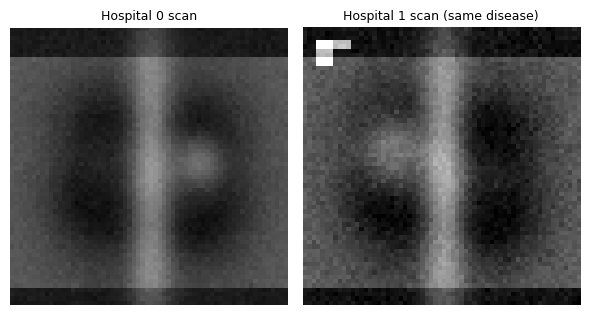

In [36]:
D_H1_TEST = build_set(_n(800), p_tag_match=0.5, site=1, seed=21)
D_H1_VAL = build_set(_n(300), p_tag_match=0.5, site=1, seed=24)
D_MIX_TRAIN = {k: torch.cat([D_TRAIN_CLEAN[k], build_set(_n(300), 0.5, site=1, seed=22)[k]]) for k in ("X", "Y", "M", "T")}
MODEL_MIX = train_classifier(SmallCNN(), D_MIX_TRAIN["X"], D_MIX_TRAIN["Y"], epochs=8 if not QUICK else 2)


def val_threshold(model: nn.Module, d: dict, target: float = 0.95) -> float:
    p, y = predict_proba(model, d["X"]).numpy(), d["Y"].numpy() == 1
    ok = [t for t in thr_grid if (p[y] >= t).mean() >= target]
    return max(ok) if ok else float(thr_grid.min())


thr_local = val_threshold(MODEL_C, D_H1_VAL)
rows = []
for nm, mdl, t, d in [("Model C @ Hospital 0 (home)", MODEL_C, 0.5, D_TEST_CLEAN),
                      ("Model C @ Hospital 1, thr 0.5", MODEL_C, 0.5, D_H1_TEST),
                      (f"Model C @ Hospital 1, thr re-chosen locally ({thr_local:.3g})", MODEL_C, thr_local, D_H1_TEST),
                      ("Model trained on BOTH hospitals @ Hospital 1, thr 0.5", MODEL_MIX, 0.5, D_H1_TEST)]:
    s_, sp_, a_ = sens_spec(mdl, d, t)
    rows.append([nm, f"{s_:.3f}", f"{sp_:.3f}", f"{a_:.3f}", f"{roc_auc_score(d['Y'].numpy(), predict_proba(mdl, d['X']).numpy()):.3f}"])
table(rows, ["setting", "sensitivity", "specificity", "accuracy", "AUC"])
show_row([D_TEST_CLEAN["X"][int(sick_idx[0]), 0].numpy(), D_H1_TEST["X"][int(torch.where(D_H1_TEST["Y"] == 1)[0][0]), 0].numpy()], ["Hospital 0 scan", "Hospital 1 scan (same disease)"], size=3, vmin=0, vmax=1)

**Reading the result.** Compare the "home" row to the "Hospital 1, thr 0.5" row: the *same* model can lose sensitivity or specificity (and sometimes AUC) purely because of the scanner. Also compare AUC to the threshold-based numbers: if AUC stays high but sensitivity drops, the model still *ranks* patients well and **recalibrating the threshold** may be enough; if AUC itself drops, the model needs new data. This is why the notes insist on testing on **external** data (another hospital) before any claim of "it works" — one hospital's test set can look excellent and still not generalise.

**Regulation, in one paragraph (§10, conceptual only).** Software that helps diagnose is regulated as a medical device (e.g. by the FDA in the US, under the CE/MDR scheme in the EU). Regulators care about intended use, clinical evidence on representative patients, performance across sub-groups and sites, risk management, and monitoring after deployment. A research notebook like this is **not** a medical device and nothing here is clinical advice or evidence of clinical performance.

# Part 10 — Wrap-up: the debugging checklist, run on our own models (§10, §11)
### 🧒 In simple words
Before you trust any medical model, ask the same six questions every time. The notes' checklist (§11) is a *habit*. Here we turn it into a small function and run it on the two models of Part 1, so you can see how it would have caught the cheat.

| # | Question | What we compute |
|---|---|---|
| 1 | Does it only work on data that looks like its training data? | accuracy on three test sets (marker agrees / random / opposite) |
| 2 | Where does it look? | share of Grad-CAM heat on the lesion vs on the marker |
| 3 | Does the explanation depend on what the model learned? | |rank correlation| with the map of a random-weight model (high = warning) |
| 4 | Does it catch the sick patients? | sensitivity and specificity at a stated threshold |
| 5 | Does it hold at another hospital? | sensitivity at Hospital 1 |
| 6 | Can someone else reproduce this? | seeds, data and settings written down (see the README cell below) |

In [37]:
def audit(model: nn.Module, name: str, n: int = 40) -> list:
    acc3 = [accuracy(model, D_TEST_BIASED), accuracy(model, D_TEST_CLEAN), accuracy(model, D_TEST_FLIPPED)]
    idx = [int(i) for i in torch.where(D_TEST_CLEAN["Y"] == 1)[0][:n]]
    les = np.mean([region_stats(grad_cam(model, model.b3, D_TEST_CLEAN["X"][i:i + 1], 1), D_TEST_CLEAN["M"][i, 0].numpy())[1] for i in idx])
    tag = np.mean([region_stats(grad_cam(model, model.b3, D_TEST_CLEAN["X"][i:i + 1], 1), tag_region())[1] for i in idx])
    sim = np.nanmean([abs(spearmanr(grad_cam(model, model.b3, D_TEST_CLEAN["X"][i:i + 1], 1).flatten().numpy(), grad_cam(RAND, RAND.b3, D_TEST_CLEAN["X"][i:i + 1], 1).flatten().numpy())[0]) for i in idx[:20]])
    se, sp, _ = sens_spec(model, D_TEST_CLEAN)
    se1, _, _ = sens_spec(model, D_H1_TEST)
    return [name, f"{acc3[0]:.2f} / {acc3[1]:.2f} / {acc3[2]:.2f}", f"{les:.2f} / {tag:.2f}", f"{sim:.2f}", f"{se:.2f} / {sp:.2f}", f"{se1:.2f}"]


table([audit(MODEL_B, "Model B (biased)"), audit(MODEL_C, "Model C (clean)")],
      ["model", "1. accuracy: biased / clean / flipped", "2. heat on lesion / marker", "3. |corr.| with random-weights map", "4. sens / spec (clean test)", "5. sens at Hospital 1"])

model             1. accuracy: biased / clean / flipped  2. heat on lesion / marker  3. |corr.| with random-weights map  4. sens / spec (clean test)  5. sens at Hospital 1
----------------  -------------------------------------  --------------------------  ----------------------------------  ---------------------------  ---------------------
Model B (biased)  0.95 / 0.51 / 0.00                     0.17 / 0.21                 0.56                                0.50 / 0.52                  1.00                 
Model C (clean)   1.00 / 1.00 / 1.00                     0.15 / 0.02                 0.82                                1.00 / 1.00                  0.73                 


**Reading the table.** Row B is the textbook warning: high accuracy on the set that shares its shortcut, a collapse on the "flipped" set (question 1), and heat that favours the marker (question 2). Row C looks healthier on 1 and 2 (but note question 3: its Grad-CAM map is strongly correlated with the random-weights map, so part of that picture reflects the image rather than learning) — and check question 5: even a model with the *right* reasons can lose sensitivity at a different hospital. A checklist item that passes does not prove safety; one that fails tells you where to look.

### 10.1 Glossary (plain words)
| Term | Meaning |
|---|---|
| Interpretable model | one you can read directly (e.g. a straight-line model's weights) |
| Explainable AI (XAI) | tools that explain a model *after* it is trained |
| Faithful explanation | one that truly reflects what the model used, not just a pretty picture |
| Saliency map | per-pixel gradient: "which pixels move the answer most?" |
| Grad-CAM | gradient-weighted blend of a conv layer's feature maps → coarse heatmap |
| Occlusion | hide a patch, measure the drop in the answer |
| LIME | local straight-line model fitted on randomly-hidden superpixels |
| Shapley / SHAP | fair share of the prediction per feature, averaged over all join-orders |
| Attention / rollout | transformer's token-to-token weights / their product through layers |
| Shortcut learning | using an easy but irrelevant cue (a marker) instead of the real cause |
| Domain gap / shift | training and deployment data differ (ImageNet→X-ray, hospital→hospital) |
| Hounsfield unit (HU) | CT density scale: air −1000, water 0, bone ≫ 0 |
| U-Net / skip connection | encoder-decoder segmenter / shortcut carrying detail to the decoder |
| Dice, IoU | overlap scores between predicted and true masks (Dice = 2·IoU/(1+IoU)) |
| Sensitivity, specificity | share of sick caught / share of healthy cleared |
| PPV | when the model says "sick", how often it is right (depends on prevalence) |
| Threshold | probability cut-off that turns a score into a decision |

### 10.2 Self-check questions (answer first, then open the answer)
1. A model scores 96 % accuracy on the hospital's test set. Name two things you would check before trusting it.
<details><summary>answer</summary>That the heatmaps point at anatomy and not at artefacts (e.g. markers); that it holds on an external hospital/scanner; sensitivity and specificity rather than accuracy; class balance of the split.</details>

2. Why is Grad-CAM from the last conv layer blurry, and what is the cost of using an earlier layer?
<details><summary>answer</summary>The last layer's maps are small (e.g. 7×7), so the upsampled heat is blocky; earlier layers are sharper but respond to generic edges/textures, so they say less about the class (Part 3.3 measured the trade-off).</details>

3. LIME gives two different explanations for the same image on two runs. Is the model broken?
<details><summary>answer</summary>Not necessarily — LIME samples randomly. Fix the seed, increase the number of samples, and report both (Part 4.4 measured how agreement grows with samples).</details>

4. A segmenter reaches 99 % pixel accuracy. Is it good?
<details><summary>answer</summary>Unknown: lesions are a tiny share of pixels, so predicting "no lesion" already scores that high. Look at Dice/IoU on images that contain lesions (Part 8.3).</details>

5. A screening test has 95 % sensitivity and 90 % specificity. Disease prevalence is 1 %. Roughly what fraction of positive results are true?
<details><summary>answer</summary>PPV = 0.95·0.01 / (0.95·0.01 + 0.10·0.99) ≈ 0.088, about 9 % — most alarms are false at low prevalence (Part 9.3).</details>

6. Your attention map looks perfect. Is that an explanation?
<details><summary>answer</summary>Only if it passes a test such as deletion; attention can look plausible without being faithful (Jain &amp; Wallace 2019 vs Wiegreffe &amp; Pinter 2019; Part 5.2).</details>

### 10.3 How Day 37 maps to the PP13 assignment (this notebook does **not** solve PP13)
| PP13 requirement (from the Day 37 PDF) | Where to practise it here | What you still have to do yourself |
|---|---|
| Task A: real image classifier, report **sensitivity and specificity at a stated threshold** | Part 9.1–9.2 (threshold chosen on validation, reported on test) | train on the real PP13 dataset; state and justify the threshold |
| Task B: **U-Net** segmentation with **Dice and IoU** | Part 8.3 | real masks, real split, per-image vs pooled metric stated |
| **Explainability on both tasks**; Task B **adapted, not copied** from Task A | Part 3 (Grad-CAM), Part 8.4 (Seg-Grad-CAM, region occlusion) | choose layers, show failures, say what each map can and cannot support |
| **Check class imbalance in the actual split** | Part 7.5 | count classes per split; pick weights/resampling; re-check sensitivity |
| **Written reflection** tied to the clinical-risk discussion (§9) | Parts 9.2–9.4 and the checklist above | your own words: threshold, shift, limits, what you would not claim |

### 10.4 Limits of this notebook (read before quoting any number)
* All **trained** models and all quantitative results use **synthetic** 64×64 images made by `make_scan`. They show how the *methods* behave when the right answer is known; they do **not** show how well any model diagnoses real disease.
* The real X-rays (Part 7.2) are only displayed. No model was trained on or evaluated on real patients.
* Numbers come from one fixed random seed per experiment (a few experiments use 3 seeds, as stated); differences smaller than the printed spread should not be read as real.
* `[assumed]` values (the 10:1 cost ratio, typical Hounsfield values, CT presets) are illustrations, not clinical recommendations.
* Nothing here is medical advice or evidence for regulatory purposes.

### 10.5 README — how to re-run
* Needs Python 3, `torch`, `torchvision`, `numpy`, `pandas`, `scipy`, `scikit-learn`, `scikit-image`, `matplotlib`, `pillow`. A GPU is not needed.
* The notebook downloads ResNet-18 weights and a metadata file/images over HTTPS from GitHub. Without internet, those cells print a message and skip; everything else still runs.
* `XAI_QUICK=1` (environment variable) shrinks all datasets and epochs for a fast smoke test (numbers then become meaningless).
* All random seeds are fixed (`SEED` in Part 0).

### 10.6 References
*(Only sources checked or well-established are listed; check the exact venue/pages before citing in a report.)*
* Selvaraju et al. (2017). *Grad-CAM: Visual Explanations from Deep Networks via Gradient-based Localization.* ICCV.
* Chattopadhay et al. (2018). *Grad-CAM++: Generalized Gradient-based Visual Explanations for Deep Convolutional Networks.* WACV.
* Vinogradova, Dibrov & Myers (2020). *Towards Interpretable Semantic Segmentation via Gradient-weighted Class Activation Mapping (Student Abstract).* AAAI. arXiv:2002.11434 (checked).
* Ribeiro, Singh & Guestrin (2016). *"Why Should I Trust You?": Explaining the Predictions of Any Classifier.* KDD.
* Lundberg & Lee (2017). *A Unified Approach to Interpreting Model Predictions.* NeurIPS.
* Jain & Wallace (2019). *Attention is not Explanation.* NAACL.   Wiegreffe & Pinter (2019). *Attention is not not Explanation.* EMNLP.
* Abnar & Zuidema (2020). *Quantifying Attention Flow in Transformers.* ACL. arXiv:2005.00928 (checked).
* Ronneberger, Fischer & Brox (2015). *U-Net: Convolutional Networks for Biomedical Image Segmentation.* MICCAI.
* He et al. (2016). *Deep Residual Learning for Image Recognition.* CVPR.
* Cohen, Morrison, Dao et al. (2020). *COVID-19 Image Data Collection: Prospective Predictions Are the Future.* (the `covid-chestxray-dataset`, github.com/ieee8023/covid-chestxray-dataset). Images shown: licence "CC BY 3.0", source github.com/ml-workgroup/covid-19-image-repository, as listed in its metadata.
* Day 37 notes: *Research Intake 2026 — Day 37: Explainable AI and Medical Imaging* (the PDF supplied with this task).

In [38]:
print(f"Total notebook run time: {(time.time() - NB_START) / 60:.1f} min on {DEVICE}  (QUICK={QUICK})")

Total notebook run time: 18.0 min on cpu  (QUICK=False)
